# Dataset B — Research EDA v2

## TL;DR

- Cohort filter giữ 293.301 trong 383.614 hồ sơ; 90.313 hồ sơ nằm ngoài `action_taken ∈ {1,2,3}`.
- Parser không phát hiện token invalid và chuyển 360 giá trị income âm thành 0.
- Special states được giữ có chủ đích; `debt_to_income_ratio` có tỷ lệ special state lớn nhất, 31.108 hồ sơ (10,61%).
- Approved chiếm 218.760 hồ sơ (74,59%); association theo target mạnh nhất là `debt_to_income_ratio` (Cramér's V ≈ 0,5168), còn numeric mạnh nhất là `loan_amount` (Spearman ρ ≈ +0,1869).
- EDA-only semantic view thêm bốn numeric status channels và 57.851 median placeholders, tăng schema từ 12 lên 16 cột nhưng giữ nguyên mọi observed numeric và categorical value.
- Không áp dụng `log1p`, OHE hoặc scaling trong notebook này.


## Data scope

Notebook sử dụng Dataset B eligible cohort từ raw state-level CSV. Mười hai predictors được lấy theo `feature_set_v1.yaml` và parse vào `eda_base`; outcome được giữ riêng trong Series `eda_target` căn hàng để phục vụ target-aware EDA. Sau acceptance gate, feature figures chỉ đọc `eda_base`, outcome figures chỉ ghép `eda_target`, và phần post-preprocessing chỉ đọc `eda_processed` được tạo từ cùng cohort.


In [1]:
# EDA v2 staging — Task 01: setup and minimal data contract
# This cell is intentionally self-contained and does not import project code from src.
from pathlib import Path

import yaml

EDA_V2_PROJECT_ROOT = next(
    path
    for path in (Path.cwd(), *Path.cwd().parents)
    if (path / "config" / "dataset_b" / "feature_set_v1.yaml").exists()
)
EDA_V2_RAW_DATA_PATH = EDA_V2_PROJECT_ROOT / "data" / "raw" / "state_NY_2024.csv"
EDA_V2_FEATURE_CONTRACT_PATH = (
    EDA_V2_PROJECT_ROOT / "config" / "dataset_b" / "feature_set_v1.yaml"
)

with EDA_V2_FEATURE_CONTRACT_PATH.open(encoding="utf-8") as handle:
    EDA_V2_FEATURE_CONTRACT = yaml.safe_load(handle)

EDA_V2_TARGET_SOURCE = EDA_V2_FEATURE_CONTRACT["target"]["source_column"]
EDA_V2_ELIGIBLE_ACTIONS = frozenset(
    str(value)
    for value in EDA_V2_FEATURE_CONTRACT["target"]["eligible_values"]
)
EDA_V2_FEATURES = tuple(EDA_V2_FEATURE_CONTRACT["model_input_raw_columns"])

EDA_V2_NUMERIC_FEATURES = (
    "income",
    "loan_amount",
    "loan_to_value_ratio",
    "loan_term",
)
EDA_V2_CATEGORICAL_FEATURES = (
    "loan_type",
    "loan_purpose",
    "lien_status",
    "reverse_mortgage",
    "open-end_line_of_credit",
    "business_or_commercial_purpose",
    "debt_to_income_ratio",
    "occupancy_type",
)

EDA_V2_NUMERIC_SPECIAL_TOKENS = {
    "income": frozenset({"NA"}),
    "loan_amount": frozenset(),
    "loan_to_value_ratio": frozenset({"NA", "Exempt"}),
    "loan_term": frozenset({"NA", "Exempt"}),
}
EDA_V2_CATEGORICAL_DOMAINS = {
    "loan_type": frozenset({"1", "2", "3", "4"}),
    "loan_purpose": frozenset({"1", "2", "31", "32", "4", "5"}),
    "lien_status": frozenset({"1", "2"}),
    "reverse_mortgage": frozenset({"1", "2", "1111"}),
    "open-end_line_of_credit": frozenset({"1", "2", "1111"}),
    "business_or_commercial_purpose": frozenset({"1", "2", "1111"}),
    "debt_to_income_ratio": frozenset(
        {
            "<20%",
            "20%-<30%",
            "30%-<36%",
            "50%-60%",
            ">60%",
            "NA",
            "Exempt",
            *(str(value) for value in range(36, 50)),
        }
    ),
    "occupancy_type": frozenset({"1", "2", "3"}),
}
EDA_V2_CATEGORICAL_SPECIAL_TOKENS = {
    "loan_type": frozenset(),
    "loan_purpose": frozenset(),
    "lien_status": frozenset(),
    "reverse_mortgage": frozenset({"1111"}),
    "open-end_line_of_credit": frozenset({"1111"}),
    "business_or_commercial_purpose": frozenset({"1111"}),
    "debt_to_income_ratio": frozenset({"NA", "Exempt"}),
    "occupancy_type": frozenset(),
}

EDA_V2_COLORS = {
    "before": "#5D6D7E",
    "after": "#2980B9",
    "special": "#D97706",
    "missing": "#BDC3C7",
    "invalid": "#C2410C",
    "reference": "#2C3E50",
    "text": "#1F2937",
    "grid": "#E5E7EB",
}
EDA_V2_SEQUENTIAL_COLORS = ("#EDF8B1", "#7FCDBB", "#1D91C0", "#225EA8", "#0C2C84")
EDA_V2_DIVERGING_COLORS = ("#00441B", "#66C2A4", "#F7F7F7", "#4292C6", "#08306B")
EDA_V2_ASSOCIATION_CMAP_NAME = "eda_v2_sequential"

assert EDA_V2_FEATURE_CONTRACT["dataset"] == "dataset_b"
assert EDA_V2_TARGET_SOURCE == "action_taken"
assert EDA_V2_ELIGIBLE_ACTIONS == {"1", "2", "3"}
assert len(EDA_V2_FEATURES) == 12
assert set(EDA_V2_NUMERIC_FEATURES).isdisjoint(EDA_V2_CATEGORICAL_FEATURES)
assert set(EDA_V2_NUMERIC_FEATURES) | set(EDA_V2_CATEGORICAL_FEATURES) == set(
    EDA_V2_FEATURES
)
assert tuple(EDA_V2_NUMERIC_SPECIAL_TOKENS) == EDA_V2_NUMERIC_FEATURES
assert tuple(EDA_V2_CATEGORICAL_DOMAINS) == EDA_V2_CATEGORICAL_FEATURES
assert tuple(EDA_V2_CATEGORICAL_SPECIAL_TOKENS) == EDA_V2_CATEGORICAL_FEATURES
assert EDA_V2_RAW_DATA_PATH.exists()

EDA_V2_TASK_01_SUMMARY = {
    "raw_data_path": str(EDA_V2_RAW_DATA_PATH),
    "feature_version": EDA_V2_FEATURE_CONTRACT["feature_version"],
    "target_source": EDA_V2_TARGET_SOURCE,
    "eligible_actions": sorted(EDA_V2_ELIGIBLE_ACTIONS),
    "feature_count": len(EDA_V2_FEATURES),
    "numeric_feature_count": len(EDA_V2_NUMERIC_FEATURES),
    "categorical_feature_count": len(EDA_V2_CATEGORICAL_FEATURES),
    "association_cmap": EDA_V2_ASSOCIATION_CMAP_NAME,
}

print("[PASS] EDA v2 Task 01 setup and minimal data contract are ready.")
EDA_V2_TASK_01_SUMMARY

# ---------------------------------------------------------------------------
# Presentation labels, units, and category descriptions
# Source: HMDA data dictionary — confirmed identifiers for Dataset B features.
# ---------------------------------------------------------------------------

EDA_V2_FEATURE_LABELS = {
    "income":                        "Annual Income",
    "loan_amount":                   "Loan Amount",
    "loan_to_value_ratio":           "Loan-to-Value Ratio",
    "loan_term":                     "Loan Term",
    "loan_type":                     "Loan Type",
    "loan_purpose":                  "Loan Purpose",
    "lien_status":                   "Lien Status",
    "reverse_mortgage":              "Reverse Mortgage",
    "open-end_line_of_credit":       "Open-End Line of Credit",
    "business_or_commercial_purpose":"Business / Commercial Purpose",
    "debt_to_income_ratio":          "Debt-to-Income Ratio",
    "occupancy_type":                "Occupancy Type",
}

# Units confirmed from HMDA Filing Instructions (2024):
#   income       — thousands of USD (integer or float, e.g. 120 = $120,000)
#   loan_amount  — thousands of USD
#   loan_to_value_ratio — percent (e.g. 74.99 = 74.99%)
#   loan_term    — months (integer, e.g. 360 = 30 years)
EDA_V2_NUMERIC_UNITS = {
    "income":              "\u0024 thousands",
    "loan_amount":         "\u0024 thousands",
    "loan_to_value_ratio": "%",
    "loan_term":           "months",
}

# Category descriptions per HMDA data dictionary.
# Raw code is retained in parentheses where it aids traceability.
EDA_V2_CATEGORY_LABELS = {
    "loan_type": {
        "1": "Conventional (1)",
        "2": "FHA-insured (2)",
        "3": "VA-guaranteed (3)",
        "4": "RHS/FSA (4)",
    },
    "loan_purpose": {
        "1":  "Home purchase (1)",
        "2":  "Home improvement (2)",
        "31": "Refinancing (31)",
        "32": "Cash-out refi (32)",
        "4":  "Other purpose (4)",
        "5":  "N/A (5)",
    },
    "lien_status": {
        "1": "First lien (1)",
        "2": "Subordinate lien (2)",
    },
    "reverse_mortgage": {
        "1":    "Is reverse mortgage (1)",
        "2":    "Not reverse mortgage (2)",
        "1111": "Exempt (1111)",
    },
    "open-end_line_of_credit": {
        "1":    "Is open-end (1)",
        "2":    "Not open-end (2)",
        "1111": "Exempt (1111)",
    },
    "business_or_commercial_purpose": {
        "1":    "Business/commercial purpose (1)",
        "2":    "Not business/commercial (2)",
        "1111": "Exempt (1111)",
    },
    "debt_to_income_ratio": {
        "<20%":    "< 20%",
        "20%-<30%":"20% – < 30%",
        "30%-<36%":"30% – < 36%",
        "NA":      "NA (not available)",
        "Exempt":  "Exempt",
        **{str(v): f"{v}% – {v+1}%" for v in range(36, 50)},
        "50%-60%": "50% – 60%",
        ">60%":    "> 60%",
    },
    "occupancy_type": {
        "1": "Principal residence (1)",
        "2": "Second residence (2)",
        "3": "Investment property (3)",
    },
}

# Assertion: every categorical domain value has a label.
for _feat, _domain in EDA_V2_CATEGORICAL_DOMAINS.items():
    _missing_labels = _domain - set(EDA_V2_CATEGORY_LABELS[_feat])
    assert not _missing_labels, (
        f"EDA_V2_CATEGORY_LABELS['{_feat}'] is missing keys: {_missing_labels}"
    )

print("[PASS] Feature labels, units, and category labels are ready.")


[PASS] EDA v2 Task 01 setup and minimal data contract are ready.
[PASS] Feature labels, units, and category labels are ready.


In [2]:
# EDA v2 — shared visual system
from matplotlib.colors import LinearSegmentedColormap

COLORS = {
    "before": "#5D6D7E",
    "after": "#2980B9",
    "special": "#D97706",
    "missing": "#BDC3C7",
    "invalid": "#C2410C",
    "reference": "#2C3E50",
}
EDA_V2_COLORS = {
    **COLORS,
    "text": "#1F2937",
    "grid": "#E5E7EB",
}
EDA_V2_ASSOCIATION_CMAP = LinearSegmentedColormap.from_list(
    EDA_V2_ASSOCIATION_CMAP_NAME, EDA_V2_SEQUENTIAL_COLORS
)
EDA_V2_DIVERGING_CMAP = LinearSegmentedColormap.from_list(
    "eda_v2_diverging", EDA_V2_DIVERGING_COLORS
)
EDA_V2_TARGET_COLORS = {"Denied": COLORS["before"], "Approved": COLORS["after"]}

EDA_V2_VISUAL_RULES = {
    "before": "slate",
    "after": "blue",
    "special": "amber + hatch",
    "missing": "light neutral + hatch",
    "invalid": "vermilion only",
    "reference": "charcoal dashed",
    "association": "sequential yellow-green-blue; diverging only for signed values",
}
assert {
    key: EDA_V2_COLORS[key] for key in COLORS
} == COLORS
print("[PASS] Shared palette and semantic visual rules are active.")


[PASS] Shared palette and semantic visual rules are active.


## Filter/parser audit

Raw data được đọc đúng một lần, lọc theo eligible actions và parse predictors vào `eda_base`; target được ánh xạ đồng thời vào `eda_target` rồi raw objects bị xóa. Bảng audit dưới đây ghi số dòng bị loại, parser changes, missing markers, special states, invalid tokens và outcome distribution. Mọi phần EDA v2 tiếp theo không quay lại raw dataframe.


In [3]:
# EDA v2 staging — Task 02: load, filter, and parse the canonical EDA base
import math

import pandas as pd

EDA_V2_TASK_02_REQUIRED = {
    "EDA_V2_RAW_DATA_PATH",
    "EDA_V2_TARGET_SOURCE",
    "EDA_V2_ELIGIBLE_ACTIONS",
    "EDA_V2_FEATURES",
    "EDA_V2_NUMERIC_FEATURES",
    "EDA_V2_CATEGORICAL_FEATURES",
    "EDA_V2_NUMERIC_SPECIAL_TOKENS",
    "EDA_V2_CATEGORICAL_DOMAINS",
    "EDA_V2_CATEGORICAL_SPECIAL_TOKENS",
}
EDA_V2_TASK_02_MISSING = sorted(
    name for name in EDA_V2_TASK_02_REQUIRED if name not in globals()
)
assert not EDA_V2_TASK_02_MISSING, (
    "Run the EDA v2 Task 01 staging cell first. Missing: "
    f"{EDA_V2_TASK_02_MISSING}"
)


def _eda_v2_is_missing(value):
    if value is None or bool(pd.isna(value)):
        return True
    return isinstance(value, str) and (
        value.strip() == "" or value.strip().lower() == "nan"
    )


def _eda_v2_parse_feature(series, feature):
    is_numeric = feature in EDA_V2_NUMERIC_FEATURES
    numeric_special = EDA_V2_NUMERIC_SPECIAL_TOKENS.get(feature, frozenset())
    categorical_domain = EDA_V2_CATEGORICAL_DOMAINS.get(feature, frozenset())
    categorical_special = EDA_V2_CATEGORICAL_SPECIAL_TOKENS.get(
        feature, frozenset()
    )

    parsed_values = []
    missing_n = 0
    special_state_n = 0
    whitespace_trimmed_n = 0
    negative_income_to_zero_n = 0
    parser_change_n = 0
    observed_n = 0
    invalid_examples = []

    for row_index, value in series.items():
        if _eda_v2_is_missing(value):
            parsed_values.append("MISSING")
            missing_n += 1
            parser_change_n += 1
            continue

        if not isinstance(value, str):
            invalid_examples.append((row_index, value, "invalid type"))
            parsed_values.append(value)
            continue

        normalized = value.strip()
        was_trimmed = normalized != value
        whitespace_trimmed_n += int(was_trimmed)

        if is_numeric:
            if normalized in numeric_special:
                parsed_values.append(normalized)
                special_state_n += 1
                parser_change_n += int(was_trimmed)
                continue
            try:
                number = float(normalized)
            except ValueError:
                invalid_examples.append((row_index, value, "invalid numeric token"))
                parsed_values.append(value)
                continue
            if not math.isfinite(number):
                invalid_examples.append((row_index, value, "non-finite numeric"))
                parsed_values.append(value)
                continue
            if feature in {"loan_amount", "loan_to_value_ratio", "loan_term"} and number <= 0:
                invalid_examples.append((row_index, value, "nonpositive numeric"))
                parsed_values.append(value)
                continue
            if feature == "loan_term" and not number.is_integer():
                invalid_examples.append((row_index, value, "non-integer loan term"))
                parsed_values.append(value)
                continue
            if feature == "income" and number < 0:
                number = 0.0
                negative_income_to_zero_n += 1
                parser_change_n += 1
            else:
                parser_change_n += int(was_trimmed)
            parsed_values.append(number)
            observed_n += 1
            continue

        if normalized not in categorical_domain:
            invalid_examples.append((row_index, value, "out-of-domain category"))
            parsed_values.append(value)
            continue
        parsed_values.append(normalized)
        special_state_n += int(normalized in categorical_special)
        parser_change_n += int(was_trimmed)
        observed_n += int(normalized not in categorical_special)

    if invalid_examples:
        preview = invalid_examples[:5]
        raise ValueError(
            f"{feature}: {len(invalid_examples):,} invalid value(s); "
            f"first examples={preview}"
        )

    audit = {
        "feature": feature,
        "row_count": len(series),
        "observed_n": observed_n,
        "missing_to_marker_n": missing_n,
        "special_state_n": special_state_n,
        "whitespace_trimmed_n": whitespace_trimmed_n,
        "negative_income_to_zero_n": negative_income_to_zero_n,
        "parser_change_n": parser_change_n,
        "invalid_n": 0,
    }
    return pd.Series(parsed_values, index=series.index, dtype=object), audit


_eda_v2_raw_source = pd.read_csv(
    EDA_V2_RAW_DATA_PATH,
    usecols=[EDA_V2_TARGET_SOURCE, *EDA_V2_FEATURES],
    dtype="string",
    keep_default_na=False,
    na_filter=False,
)
_eda_v2_raw_rows = len(_eda_v2_raw_source)
_eda_v2_eligible_mask = _eda_v2_raw_source[EDA_V2_TARGET_SOURCE].isin(
    EDA_V2_ELIGIBLE_ACTIONS
)
_eda_v2_filtered_target = _eda_v2_raw_source.loc[
    _eda_v2_eligible_mask, EDA_V2_TARGET_SOURCE
].map({"1": 1, "2": 1, "3": 0})
eda_target = _eda_v2_filtered_target.reset_index(drop=True).astype("int8")
eda_target.name = "approved"
_eda_v2_filtered_source = _eda_v2_raw_source.loc[
    _eda_v2_eligible_mask, list(EDA_V2_FEATURES)
].copy()
_eda_v2_filtered_rows = len(_eda_v2_filtered_source)

_eda_v2_parsed_columns = {}
_eda_v2_parser_audit_rows = []
for _eda_v2_feature in EDA_V2_FEATURES:
    _eda_v2_parsed, _eda_v2_audit = _eda_v2_parse_feature(
        _eda_v2_filtered_source[_eda_v2_feature], _eda_v2_feature
    )
    _eda_v2_parsed_columns[_eda_v2_feature] = _eda_v2_parsed
    _eda_v2_parser_audit_rows.append(_eda_v2_audit)

eda_base = pd.DataFrame(
    _eda_v2_parsed_columns,
    index=_eda_v2_filtered_source.index,
).reset_index(drop=True)
eda_v2_filter_audit = pd.DataFrame(
    {
        "metric": [
            "raw_rows",
            "filtered_rows",
            "excluded_rows",
            "feature_count",
        ],
        "value": [
            _eda_v2_raw_rows,
            _eda_v2_filtered_rows,
            _eda_v2_raw_rows - _eda_v2_filtered_rows,
            len(EDA_V2_FEATURES),
        ],
    }
)
eda_v2_parser_audit = pd.DataFrame(_eda_v2_parser_audit_rows)
eda_v2_target_audit = (
    eda_target.map({1: "Approved", 0: "Denied"})
    .value_counts()
    .rename_axis("outcome")
    .rename("records")
    .reset_index()
)
eda_v2_target_audit["share_pct"] = (
    eda_v2_target_audit["records"] / len(eda_target) * 100
)

assert tuple(eda_base.columns) == EDA_V2_FEATURES
assert eda_base.shape == (_eda_v2_filtered_rows, len(EDA_V2_FEATURES))
assert len(eda_target) == len(eda_base)
assert set(eda_target.unique()) == {0, 1}
assert not eda_base.isna().to_numpy().any()
assert eda_v2_parser_audit["row_count"].eq(_eda_v2_filtered_rows).all()
assert eda_v2_parser_audit["invalid_n"].eq(0).all()
assert not any(
    isinstance(value, (int, float)) and value < 0
    for value in eda_base["income"]
)

EDA_V2_TASK_02_SUMMARY = {
    "raw_rows": _eda_v2_raw_rows,
    "filtered_rows": _eda_v2_filtered_rows,
    "excluded_rows": _eda_v2_raw_rows - _eda_v2_filtered_rows,
    "eda_base_shape": eda_base.shape,
    "approved_rows": int(eda_target.eq(1).sum()),
    "denied_rows": int(eda_target.eq(0).sum()),
    "parser_change_n": int(eda_v2_parser_audit["parser_change_n"].sum()),
    "invalid_n": int(eda_v2_parser_audit["invalid_n"].sum()),
    "missing_to_marker_n": int(
        eda_v2_parser_audit["missing_to_marker_n"].sum()
    ),
    "special_state_n": int(
        eda_v2_parser_audit["special_state_n"].sum()
    ),
    "negative_income_to_zero_n": int(
        eda_v2_parser_audit["negative_income_to_zero_n"].sum()
    ),
}

# Acceptance boundary: downstream feature EDA consumes eda_base; target-aware
# figures consume only the aligned eda_target. Raw source objects are deleted.
del (
    _eda_v2_raw_source,
    _eda_v2_eligible_mask,
    _eda_v2_filtered_target,
    _eda_v2_filtered_source,
    _eda_v2_parsed_columns,
    _eda_v2_parser_audit_rows,
    _eda_v2_parsed,
    _eda_v2_audit,
    _eda_v2_feature,
)

print("[DATA QUALITY] EDA v2 filter audit")
print(eda_v2_filter_audit.to_string(index=False))
print("\n[DATA QUALITY] EDA v2 parser audit")
print(eda_v2_parser_audit.to_string(index=False))
print("\n[DATA QUALITY] Outcome distribution")
print(eda_v2_target_audit.to_string(index=False, formatters={"share_pct": "{:.2f}".format}))
print("\n[PASS] eda_base and its aligned eda_target are the only downstream data objects.")
EDA_V2_TASK_02_SUMMARY


[DATA QUALITY] EDA v2 filter audit
       metric  value
     raw_rows 383614
filtered_rows 293301
excluded_rows  90313
feature_count     12

[DATA QUALITY] EDA v2 parser audit
                       feature  row_count  observed_n  missing_to_marker_n  special_state_n  whitespace_trimmed_n  negative_income_to_zero_n  parser_change_n  invalid_n
                     loan_type     293301      293301                    0                0                     0                          0                0          0
                  loan_purpose     293301      293301                    0                0                     0                          0                0          0
                   lien_status     293301      293301                    0                0                     0                          0                0          0
              reverse_mortgage     293301      284665                    0             8636                     0                          0        

{'raw_rows': 383614,
 'filtered_rows': 293301,
 'excluded_rows': 90313,
 'eda_base_shape': (293301, 12),
 'approved_rows': 218760,
 'denied_rows': 74541,
 'parser_change_n': 360,
 'invalid_n': 0,
 'missing_to_marker_n': 0,
 'special_state_n': 114538,
 'negative_income_to_zero_n': 360}

## Part A — Parsed data before model preprocessing

`eda_base` đã đi qua cohort filter và parser của notebook. Phần này mô tả dữ liệu trước mọi bước học từ dữ liệu hoặc biến đổi phục vụ model: chưa impute, chưa tạo value/status channels, chưa encode, chưa log và chưa scale.


In [4]:
# EDA v2 staging — Task 03A: plot-ready views and coverage audit
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.patches import Patch
from matplotlib.ticker import FuncFormatter, PercentFormatter

assert "eda_base" in globals(), "Run EDA v2 Tasks 01–02 first."
assert tuple(eda_base.columns) == EDA_V2_FEATURES

eda_v2_before = eda_base.copy(deep=True)
eda_v2_numeric_before = pd.DataFrame(index=eda_v2_before.index)
eda_v2_numeric_status_before = pd.DataFrame(index=eda_v2_before.index)

for feature in EDA_V2_NUMERIC_FEATURES:
    special_tokens = EDA_V2_NUMERIC_SPECIAL_TOKENS[feature]
    values = eda_v2_before[feature]
    eda_v2_numeric_before[feature] = pd.to_numeric(
        values.mask(values.isin(special_tokens | {"MISSING"})),
        errors="raise",
    ).astype("float64")
    eda_v2_numeric_status_before[feature] = values.map(
        lambda value: (
            value
            if isinstance(value, str) and value in special_tokens | {"MISSING"}
            else "OBSERVED"
        )
    ).astype("string")

eda_v2_categorical_before = eda_v2_before.loc[
    :, list(EDA_V2_CATEGORICAL_FEATURES)
].copy(deep=True)

eda_v2_coverage_rows = []
for feature in EDA_V2_FEATURES:
    if feature in EDA_V2_NUMERIC_FEATURES:
        status = eda_v2_numeric_status_before[feature]
        observed_n = int(status.eq("OBSERVED").sum())
        missing_n = int(status.eq("MISSING").sum())
        special_n = int((~status.isin({"OBSERVED", "MISSING"})).sum())
    else:
        values = eda_v2_categorical_before[feature]
        missing_n = int(values.eq("MISSING").sum())
        special_n = int(
            values.isin(EDA_V2_CATEGORICAL_SPECIAL_TOKENS[feature]).sum()
        )
        observed_n = len(values) - missing_n - special_n
    eda_v2_coverage_rows.append(
        {
            "feature": feature,
            "observed_n": observed_n,
            "special_n": special_n,
            "missing_n": missing_n,
            "observed_pct": observed_n / len(eda_v2_before) * 100,
            "special_pct": special_n / len(eda_v2_before) * 100,
            "missing_pct": missing_n / len(eda_v2_before) * 100,
        }
    )

eda_v2_coverage_audit = pd.DataFrame(eda_v2_coverage_rows)
assert (
    eda_v2_coverage_audit[["observed_n", "special_n", "missing_n"]]
    .sum(axis=1)
    .eq(len(eda_v2_before))
    .all()
)
assert eda_v2_before.equals(eda_base)

sns.set_theme(style="whitegrid", context="notebook", font_scale=0.95)
print("[DATA QUALITY] Parsed coverage before model preprocessing")
print(
    eda_v2_coverage_audit.to_string(
        index=False,
        formatters={
            "observed_pct": "{:.2f}".format,
            "special_pct": "{:.2f}".format,
            "missing_pct": "{:.2f}".format,
        },
    )
)


[DATA QUALITY] Parsed coverage before model preprocessing
                       feature  observed_n  special_n  missing_n observed_pct special_pct missing_pct
                     loan_type      293301          0          0       100.00        0.00        0.00
                  loan_purpose      293301          0          0       100.00        0.00        0.00
                   lien_status      293301          0          0       100.00        0.00        0.00
              reverse_mortgage      284665       8636          0        97.06        2.94        0.00
       open-end_line_of_credit      284979       8322          0        97.16        2.84        0.00
business_or_commercial_purpose      284680       8621          0        97.06        2.94        0.00
                        income      272723      20578          0        92.98        7.02        0.00
          debt_to_income_ratio      262193      31108          0        89.39       10.61        0.00
                   loan_

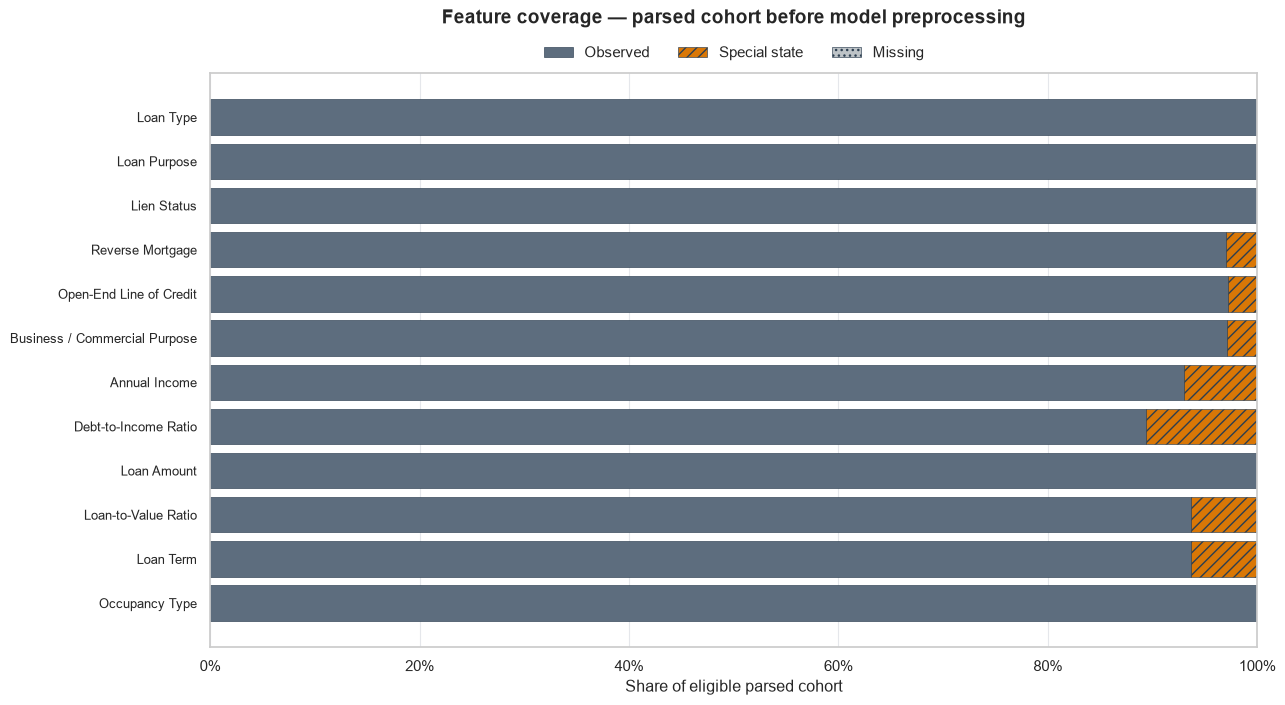

In [5]:
# EDA v2 staging — Task 03B: coverage and special-state distribution
_coverage_plot = eda_v2_coverage_audit.set_index("feature").loc[
    list(reversed(EDA_V2_FEATURES))
]
eda_v2_coverage_figure, eda_v2_coverage_axis = plt.subplots(
    figsize=(13, 7.2)
)
left = np.zeros(len(_coverage_plot))
for column, label, color, hatch in (
    ("observed_pct", "Observed", EDA_V2_COLORS["before"], None),
    ("special_pct", "Special state", EDA_V2_COLORS["special"], "///"),
    ("missing_pct", "Missing", EDA_V2_COLORS["missing"], "..."),
):
    bars = eda_v2_coverage_axis.barh(
        _coverage_plot.index,
        _coverage_plot[column],
        left=left,
        color=color,
        edgecolor=EDA_V2_COLORS["reference"],
        linewidth=0.45,
        label=label,
    )
    if hatch:
        for bar in bars:
            bar.set_hatch(hatch)
    left += _coverage_plot[column].to_numpy()

eda_v2_coverage_axis.set_xlim(0, 100)
eda_v2_coverage_axis.xaxis.set_major_formatter(PercentFormatter(100))
eda_v2_coverage_axis.set_xlabel("Share of eligible parsed cohort")
eda_v2_coverage_axis.set_ylabel("")
# Use human-readable feature labels on y-axis (FixedLocator first)
from matplotlib.ticker import FixedLocator
_c8_ticks = eda_v2_coverage_axis.get_yticks()
eda_v2_coverage_axis.yaxis.set_major_locator(FixedLocator(_c8_ticks))
eda_v2_coverage_axis.set_yticklabels(
    [EDA_V2_FEATURE_LABELS.get(lbl.get_text(), lbl.get_text())
     for lbl in eda_v2_coverage_axis.get_yticklabels()],
    fontsize=9.5,
)
del _c8_ticks
eda_v2_coverage_axis.set_title(
    "Feature coverage — parsed cohort before model preprocessing",
    fontsize=14,
    fontweight="bold",
    pad=36,
)
eda_v2_coverage_axis.legend(
    loc="lower center",
    bbox_to_anchor=(0.5, 1.0),
    ncol=3,
    frameon=False,
)
eda_v2_coverage_axis.grid(
    True, axis="x", color=EDA_V2_COLORS["grid"], linewidth=0.8
)
eda_v2_coverage_axis.grid(False, axis="y")
eda_v2_coverage_figure.tight_layout()
plt.show()

del _coverage_plot, left


**Figure 0 — Feature coverage and special-state distribution.**  
Population: eligible Dataset B cohort, *n* = 293,301 per feature. Stage: filter + parser output (`eda_base`). Each bar = share of the eligible cohort in three mutually exclusive reporting states: OBSERVED (slate), special state (amber hatched), MISSING (light hatched). Numeric special states: NA and Exempt. Categorical special states: NA, Exempt, and Exempt-1111 where applicable. *Caveat:* MISSING count is 0 for all features in this cohort; the category is shown for completeness.

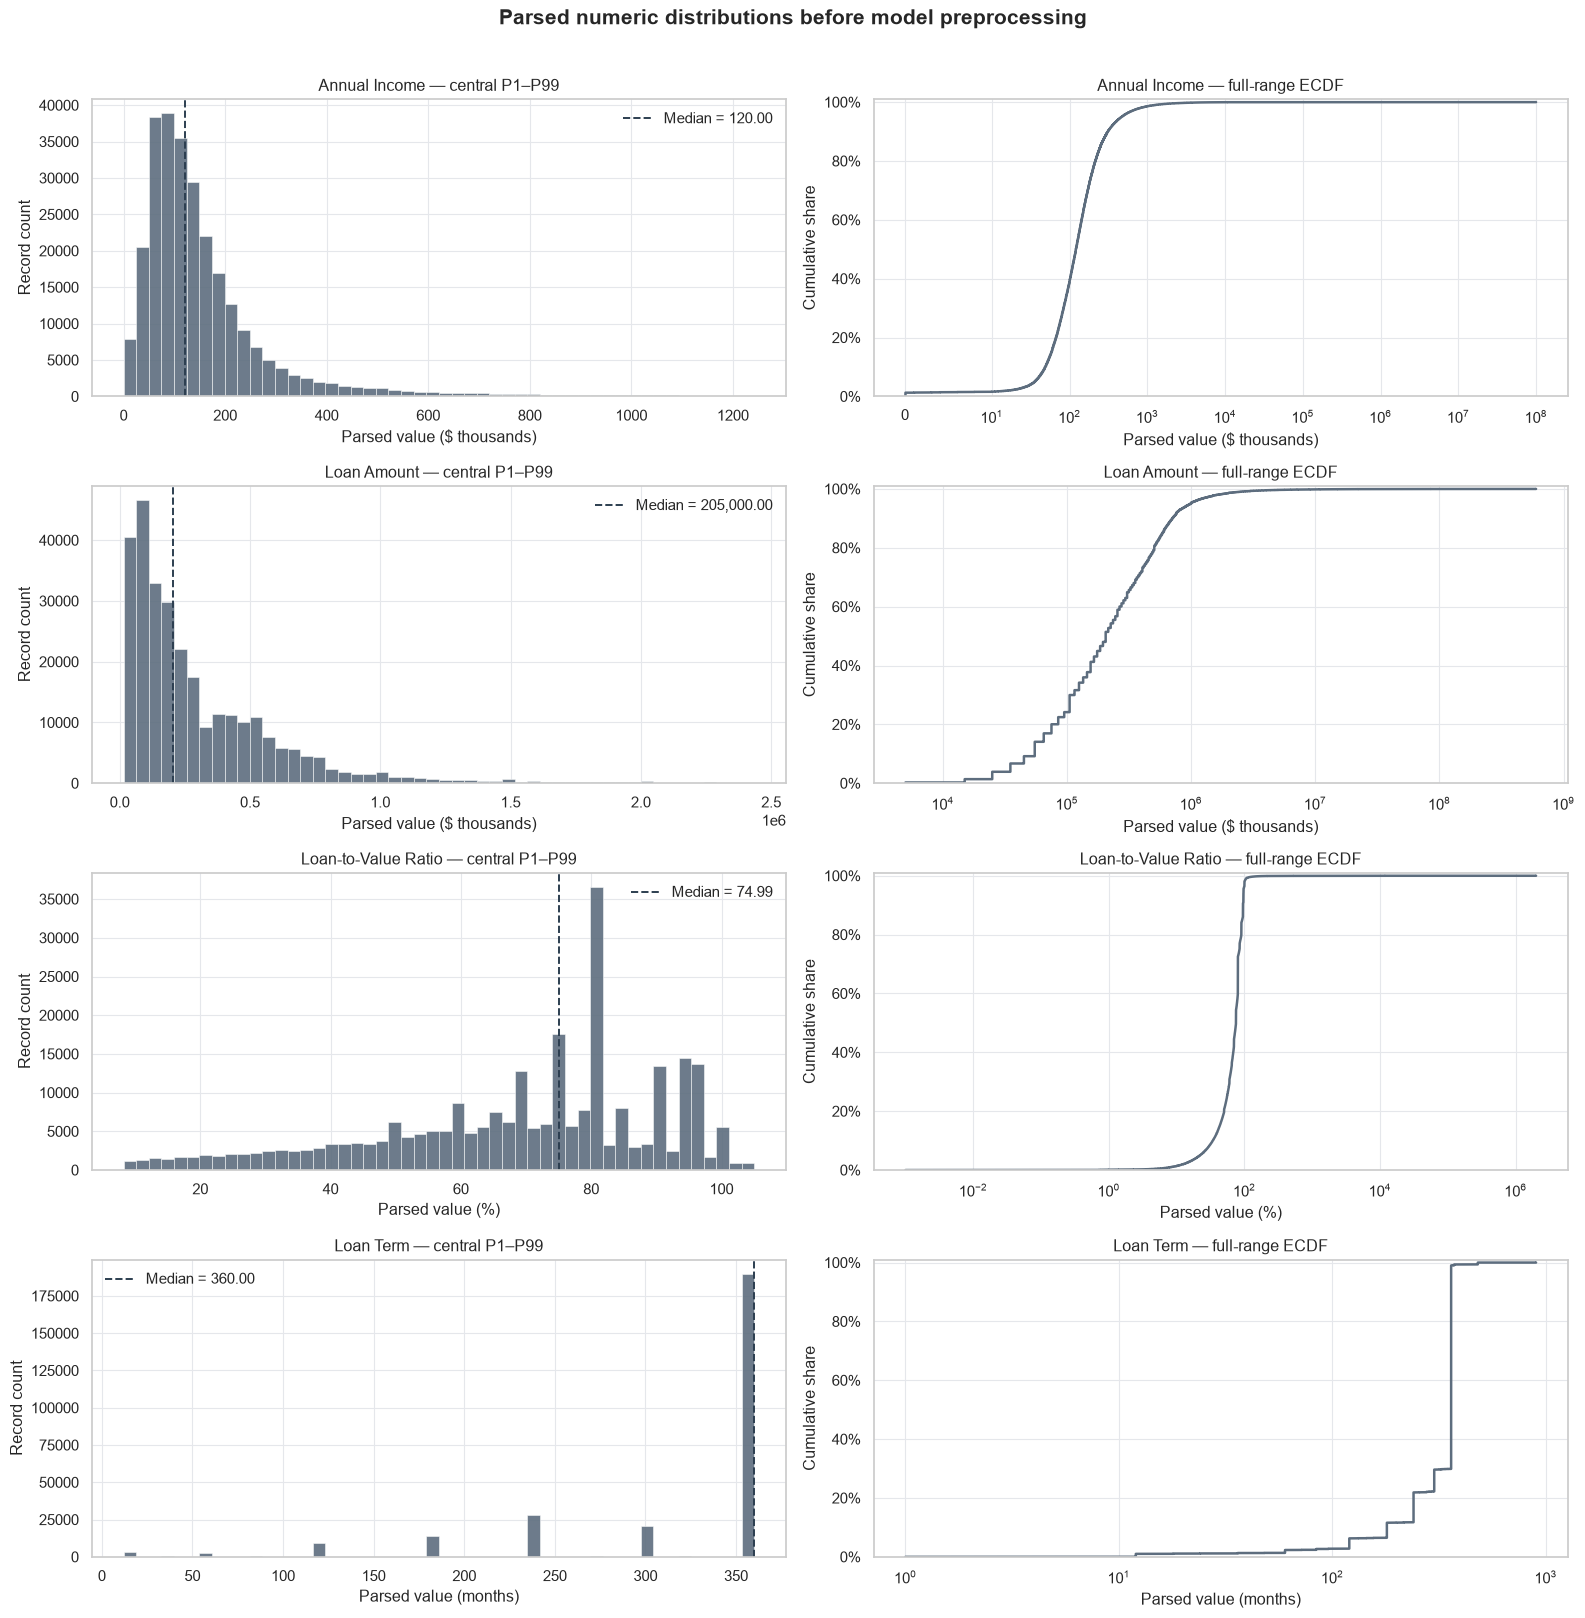

[RESULT] Numeric summary and outlier visibility
            feature  observed_n  minimum       p01    median         p99     maximum  iqr_outlier_n  special_n
             income      272723    0.000     0.000    120.00    1242.000 100000000.0          20919      20578
        loan_amount      293301 5000.000 15000.000 205000.00 2435000.000 600855000.0          16513          0
loan_to_value_ratio      274681    0.001     8.235     74.99     105.021   2000000.0           5749      18620
          loan_term      274648    1.000    12.000    360.00     360.000       900.0          33728      18653


In [6]:
# EDA v2 staging — Task 03C: numeric distributions and tail visibility
eda_v2_numeric_summary_rows = []
for feature in EDA_V2_NUMERIC_FEATURES:
    values = eda_v2_numeric_before[feature].dropna()
    q1 = float(values.quantile(0.25))
    q3 = float(values.quantile(0.75))
    iqr = q3 - q1
    lower_fence = q1 - 1.5 * iqr
    upper_fence = q3 + 1.5 * iqr
    eda_v2_numeric_summary_rows.append(
        {
            "feature": feature,
            "observed_n": len(values),
            "minimum": float(values.min()),
            "p01": float(values.quantile(0.01)),
            "median": float(values.median()),
            "p99": float(values.quantile(0.99)),
            "maximum": float(values.max()),
            "iqr_outlier_n": int(
                ((values < lower_fence) | (values > upper_fence)).sum()
            ),
            "special_n": int(
                eda_v2_coverage_audit.set_index("feature")
                .loc[feature, "special_n"]
            ),
        }
    )
eda_v2_numeric_summary = pd.DataFrame(eda_v2_numeric_summary_rows)

eda_v2_numeric_figure, eda_v2_numeric_axes = plt.subplots(
    len(EDA_V2_NUMERIC_FEATURES),
    2,
    figsize=(16, 16),
)
for row_index, feature in enumerate(EDA_V2_NUMERIC_FEATURES):
    values = eda_v2_numeric_before[feature].dropna()
    central_lower = float(values.quantile(0.01))
    central_upper = float(values.quantile(0.99))
    central = values.between(central_lower, central_upper, inclusive="both")

    distribution_axis = eda_v2_numeric_axes[row_index, 0]
    distribution_axis.hist(
        values.loc[central],
        bins=50,
        color=EDA_V2_COLORS["before"],
        edgecolor="white",
        linewidth=0.4,
        alpha=0.9,
    )
    distribution_axis.axvline(
        values.median(),
        color=EDA_V2_COLORS["reference"],
        linestyle="--",
        linewidth=1.4,
        label=f"Median = {values.median():,.2f}",
    )
    _feat_label = EDA_V2_FEATURE_LABELS.get(feature, feature)
    _unit = EDA_V2_NUMERIC_UNITS.get(feature, "")
    distribution_axis.set_title(f"{_feat_label} — central P1–P99")
    distribution_axis.set_xlabel(f"Parsed value ({_unit})" if _unit else "Parsed value")
    distribution_axis.set_ylabel("Record count")
    distribution_axis.legend(frameon=False)

    tail_axis = eda_v2_numeric_axes[row_index, 1]
    sorted_values = np.sort(values.to_numpy())
    cumulative = np.arange(1, len(sorted_values) + 1) / len(sorted_values)
    tail_axis.step(
        sorted_values,
        cumulative,
        where="post",
        color=EDA_V2_COLORS["before"],
        linewidth=1.8,
    )
    if feature == "income":
        tail_axis.set_xscale("symlog", linthresh=10)
    elif (sorted_values > 0).all():
        tail_axis.set_xscale("log")
    tail_axis.yaxis.set_major_formatter(PercentFormatter(1))
    tail_axis.set_ylim(0, 1.01)
    tail_axis.set_title(f"{_feat_label} — full-range ECDF")
    tail_axis.set_xlabel(f"Parsed value ({_unit})" if _unit else "Parsed value")
    tail_axis.set_ylabel("Cumulative share")

for axis in eda_v2_numeric_axes.flat:
    axis.grid(True, color=EDA_V2_COLORS["grid"], linewidth=0.8)

eda_v2_numeric_figure.suptitle(
    "Parsed numeric distributions before model preprocessing",
    fontsize=15,
    fontweight="bold",
    y=1.01,
)
eda_v2_numeric_figure.tight_layout()
plt.show()

print("[RESULT] Numeric summary and outlier visibility")
print(eda_v2_numeric_summary.to_string(index=False))


**Figure 1 — Parsed numeric distributions before model preprocessing.**  
Population: eligible Dataset B cohort. Stage: filter + parser output (`eda_base`). Left column = central distribution (P1–P99 window, 50-bin histogram). Right column = full-range ECDF including zero and extreme values. Charcoal dashed line = median (observed rows only). Units: Annual Income in \$\,thousands (symlog x-axis; 360 negative values were mapped to zero by parser); Loan Amount in \$\,thousands (log scale); LTV Ratio in % (log scale); Loan Term in months (log scale). Counts shown are observed-only and exclude NA / Exempt rows. *Caveat:* central windows clip at P1 and P99 to improve readability; full tails are visible in the ECDF panels.

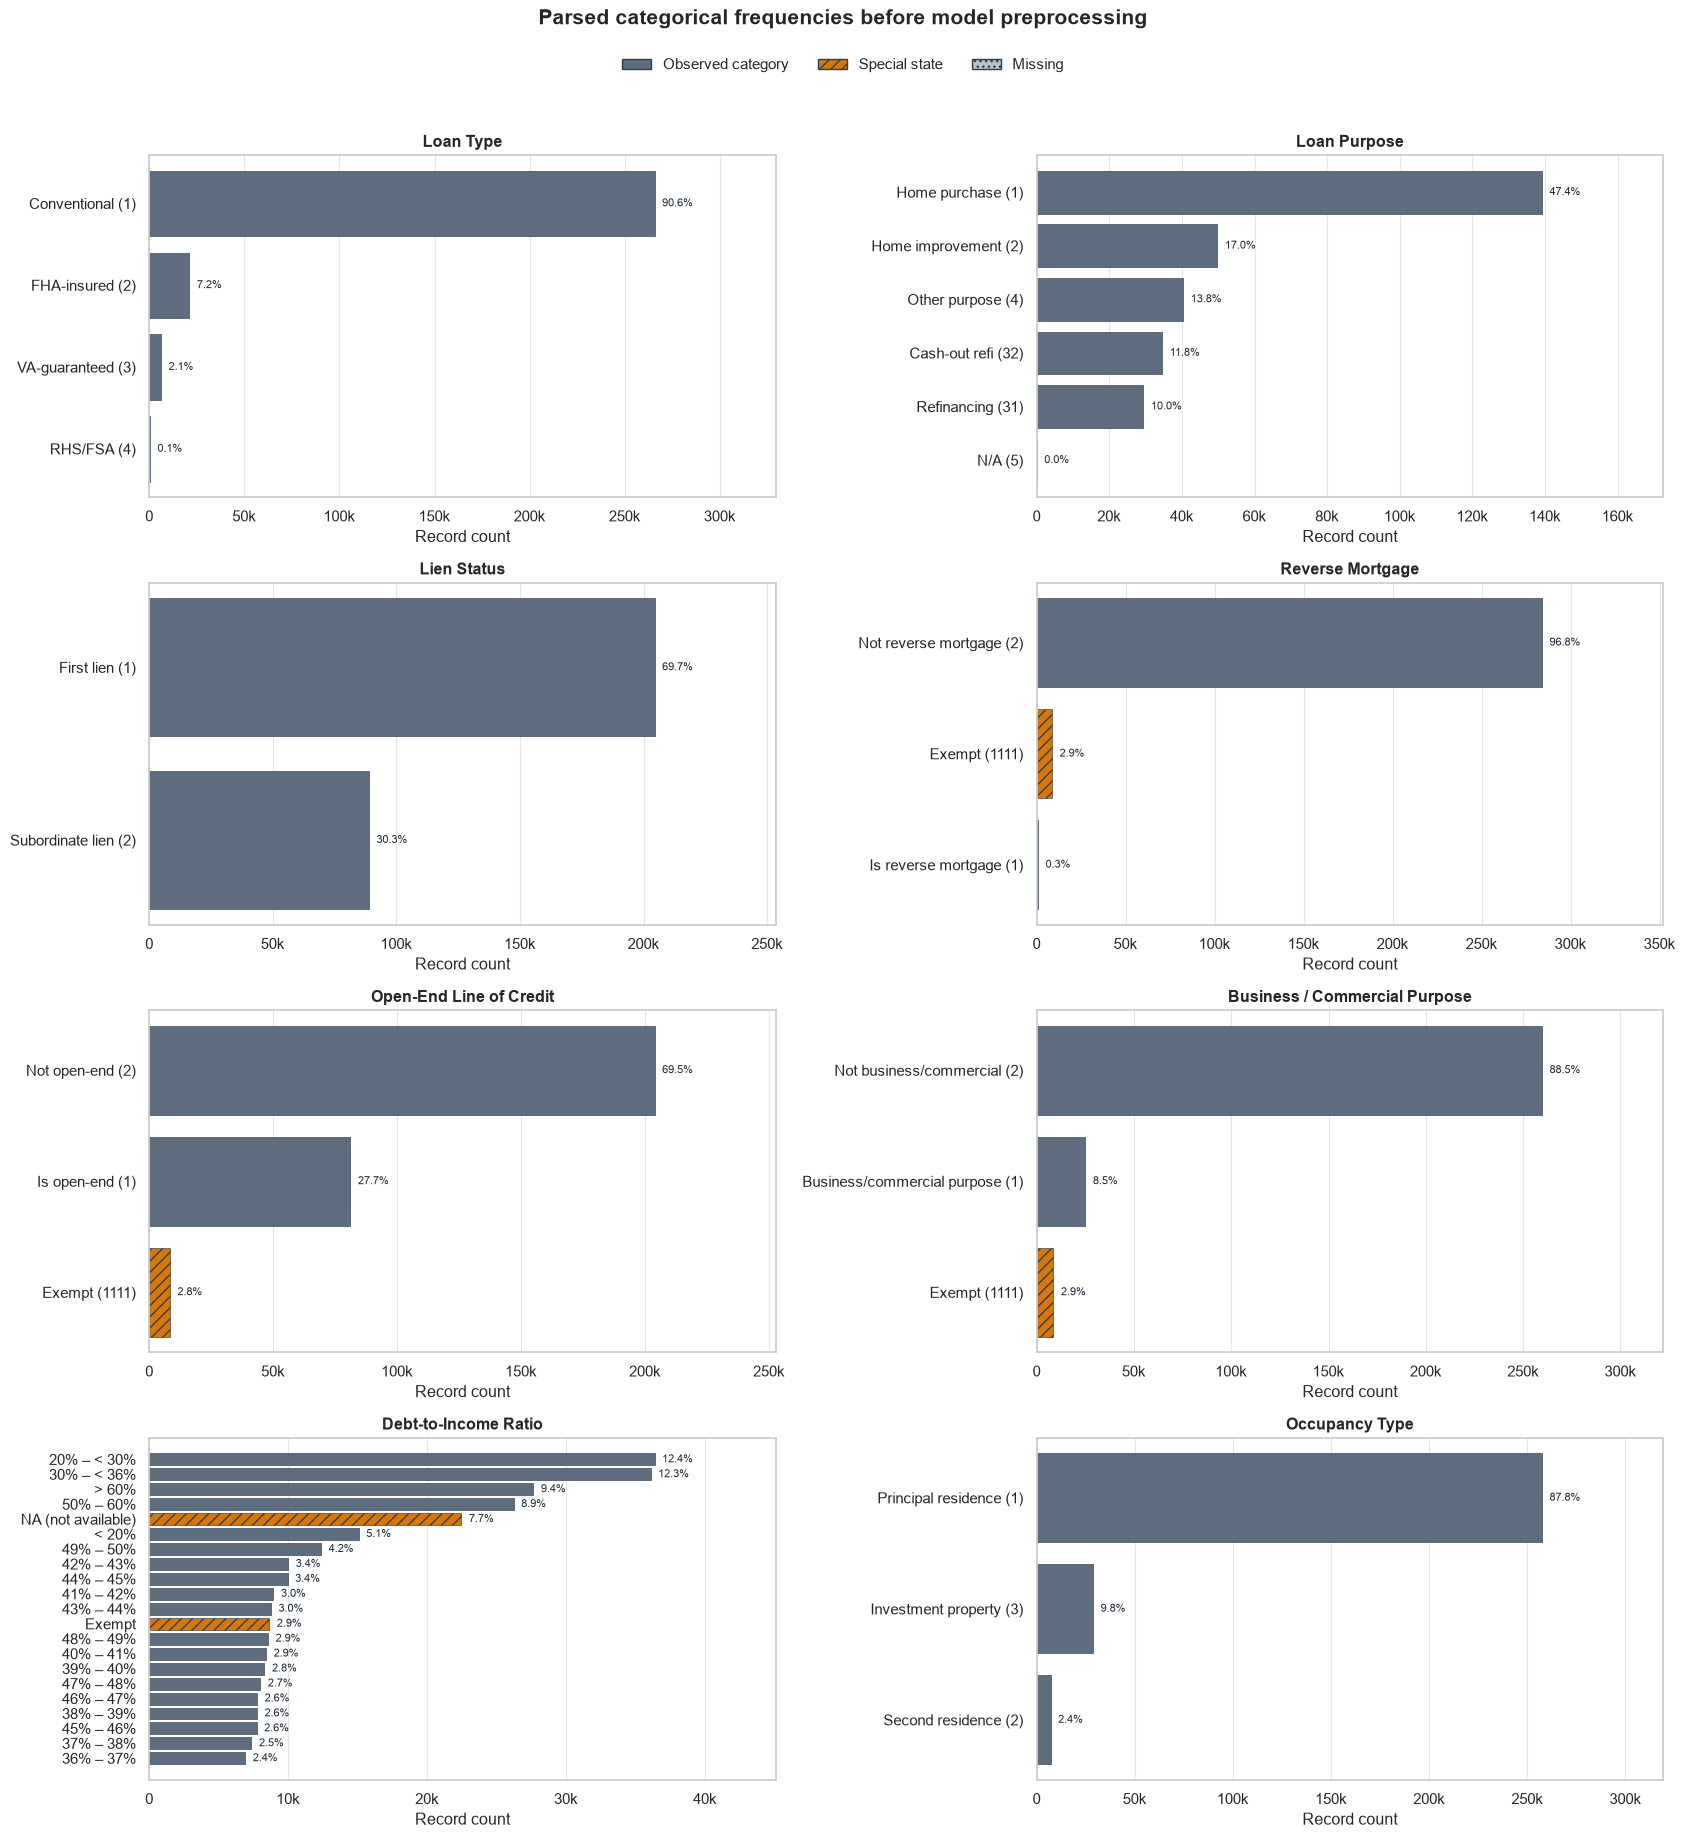

In [7]:
# EDA v2 staging — Task 03D: categorical frequencies
eda_v2_categorical_frequency_rows = []
for feature in EDA_V2_CATEGORICAL_FEATURES:
    counts = eda_v2_categorical_before[feature].value_counts(
        dropna=False, sort=False
    )
    ordered = sorted(counts.index.astype(str))
    for category in ordered:
        count = int(counts.loc[category])
        eda_v2_categorical_frequency_rows.append(
            {
                "feature": feature,
                "category": category,
                "n": count,
                "share_pct": count / len(eda_v2_before) * 100,
                "state": (
                    "missing"
                    if category == "MISSING"
                    else "special"
                    if category in EDA_V2_CATEGORICAL_SPECIAL_TOKENS[feature]
                    else "observed"
                ),
            }
        )
eda_v2_categorical_frequency = pd.DataFrame(
    eda_v2_categorical_frequency_rows
)

eda_v2_categorical_figure, eda_v2_categorical_axes = plt.subplots(
    4, 2, figsize=(17, 18)
)
for axis, feature in zip(
    eda_v2_categorical_axes.flat, EDA_V2_CATEGORICAL_FEATURES
):
    _cat_label_map = EDA_V2_CATEGORY_LABELS.get(feature, {})
    plot_data = (
        eda_v2_categorical_frequency.loc[
            eda_v2_categorical_frequency["feature"].eq(feature)
        ]
        .sort_values(["n", "category"], ascending=[True, True])
        .reset_index(drop=True)
    )
    plot_data = plot_data.assign(
        display_label=plot_data["category"].map(
            lambda c: _cat_label_map.get(str(c), str(c))
        )
    )
    colors = plot_data["state"].map(
        {
            "observed": EDA_V2_COLORS["before"],
            "special": EDA_V2_COLORS["special"],
            "missing": EDA_V2_COLORS["missing"],
        }
    )
    bars = axis.barh(
        plot_data["display_label"],
        plot_data["n"],
        color=colors,
        edgecolor=EDA_V2_COLORS["reference"],
        linewidth=0.45,
    )
    for bar, state in zip(bars, plot_data["state"]):
        if state == "special":
            bar.set_hatch("///")
        elif state == "missing":
            bar.set_hatch("...")
    maximum = max(float(plot_data["n"].max()), 1.0)
    axis.set_xlim(0, maximum * 1.24)
    axis.set_title(EDA_V2_FEATURE_LABELS.get(feature, feature), fontweight="bold")
    axis.set_xlabel("Record count")
    axis.set_ylabel("")
    axis.xaxis.set_major_formatter(
        FuncFormatter(
            lambda value, _: (
                f"{value / 1_000:.0f}k" if value >= 1_000 else f"{value:.0f}"
            )
        )
    )
    for bar, row in zip(bars, plot_data.itertuples(index=False)):
        axis.text(
            bar.get_width() + maximum * 0.015,
            bar.get_y() + bar.get_height() / 2,
            f"{row.share_pct:.1f}%",
            va="center",
            fontsize=8,
            color=EDA_V2_COLORS["text"],
        )
    axis.grid(True, axis="x", color=EDA_V2_COLORS["grid"], linewidth=0.8)
    axis.grid(False, axis="y")

eda_v2_categorical_figure.legend(
    handles=[
        Patch(
            facecolor=EDA_V2_COLORS["before"],
            edgecolor=EDA_V2_COLORS["reference"],
            label="Observed category",
        ),
        Patch(
            facecolor=EDA_V2_COLORS["special"],
            edgecolor=EDA_V2_COLORS["reference"],
            hatch="///",
            label="Special state",
        ),
        Patch(
            facecolor=EDA_V2_COLORS["missing"],
            edgecolor=EDA_V2_COLORS["reference"],
            hatch="...",
            label="Missing",
        ),
    ],
    loc="upper center",
    bbox_to_anchor=(0.5, 1.0),
    ncol=3,
    frameon=False,
)
eda_v2_categorical_figure.suptitle(
    "Parsed categorical frequencies before model preprocessing",
    fontsize=15,
    fontweight="bold",
    y=1.02,
)
eda_v2_categorical_figure.tight_layout(rect=(0, 0, 1, 0.98))
plt.show()


**Figure 2 — Parsed categorical frequencies before model preprocessing.**  
Population: eligible Dataset B cohort, *n* = 293,301 per feature. Stage: filter + parser output (`eda_base`). Bar length = record count; label = share of cohort. Slate bars = observed categories; amber hatched bars = special states (NA / Exempt / Exempt-1111); light hatched bars = MISSING. Raw HMDA codes are shown in parentheses for traceability. *Caveat:* code `1111` denotes Exempt in the three transaction-characteristic fields (Reverse Mortgage, Open-End Line of Credit, Business/Commercial Purpose) and is treated as a categorical special state, not a numeric token.

### Target-aware EDA — outcome relationships

Target được giữ ngoài 12-feature contract dưới dạng Series `eda_target` căn hàng với `eda_base`: action 1/2 = Approved, action 3 = Denied. Numeric features dùng signed Spearman ρ; categorical features dùng bias-corrected Cramér's V. Các hình sau là univariate descriptive evidence, không phải quan hệ nhân quả hoặc model feature importance.

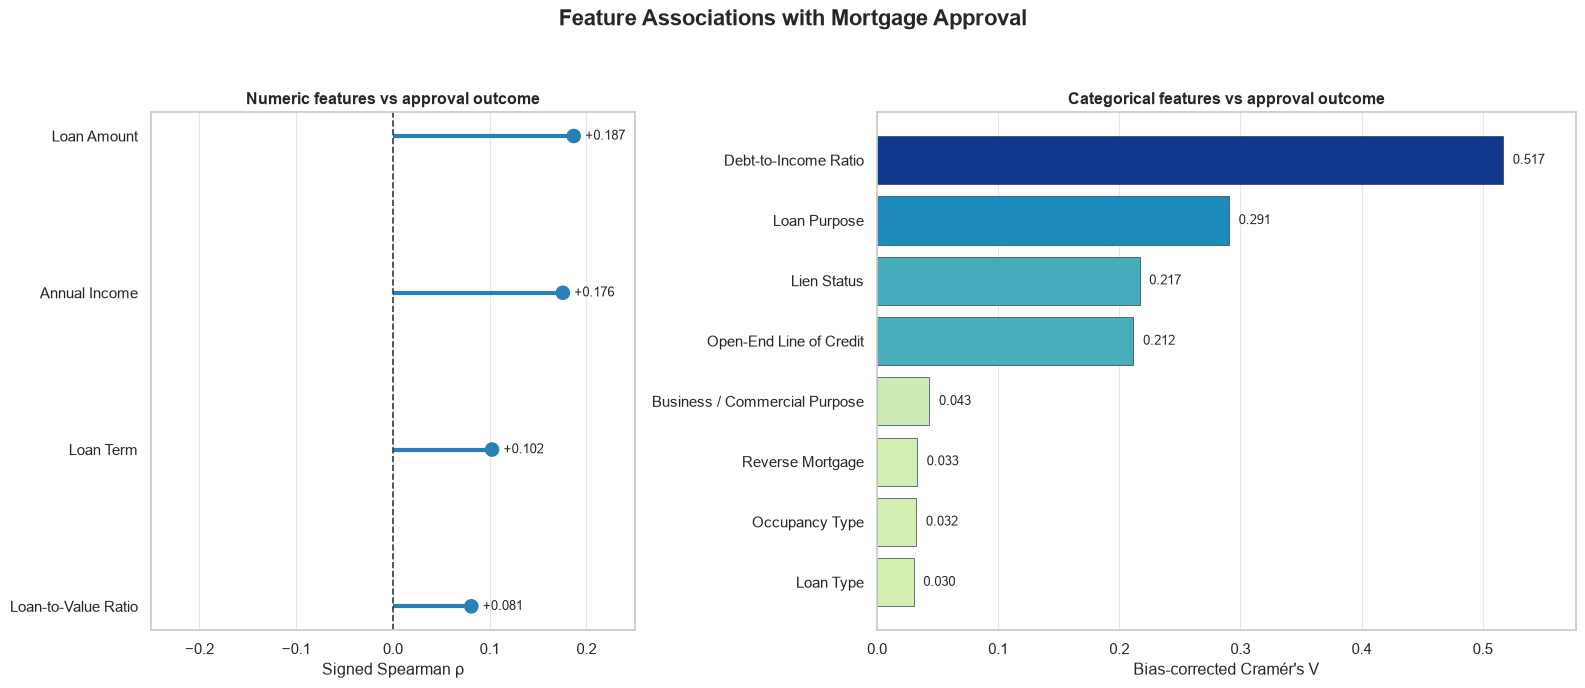

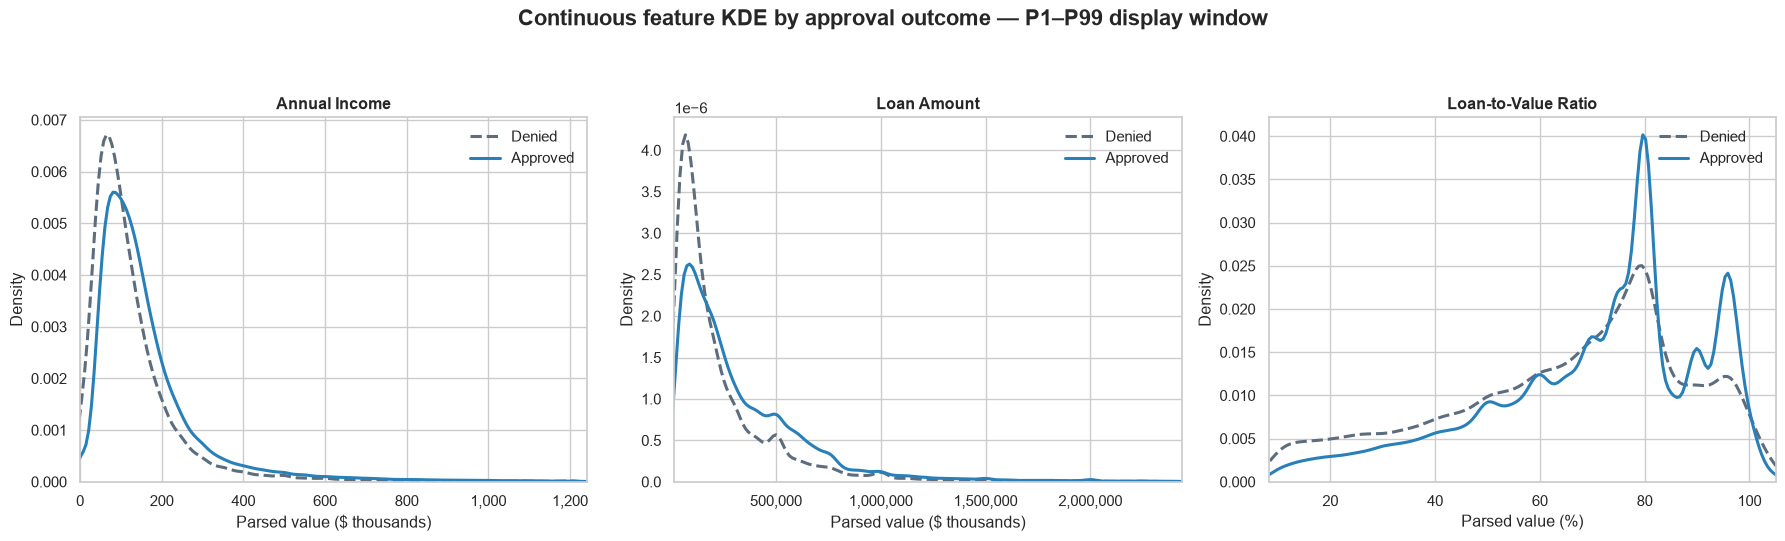

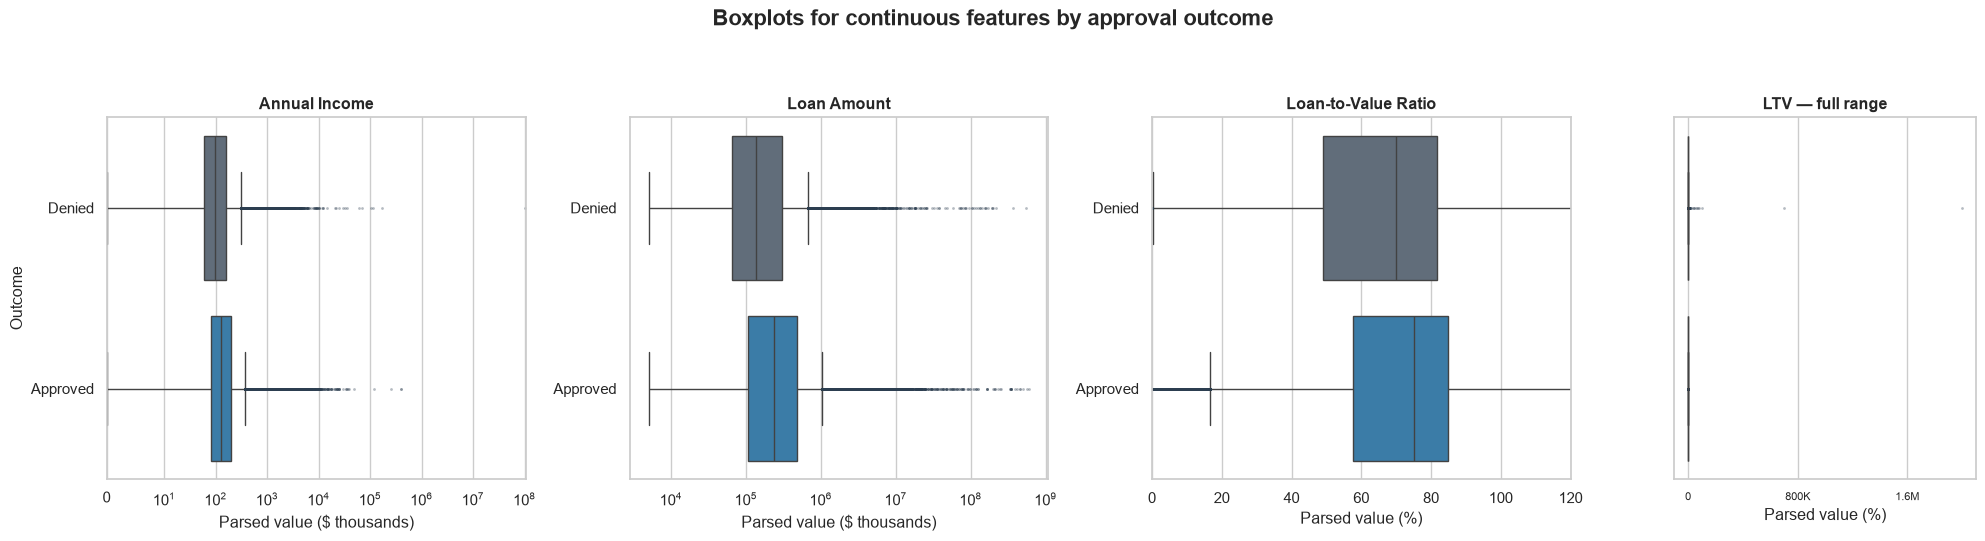

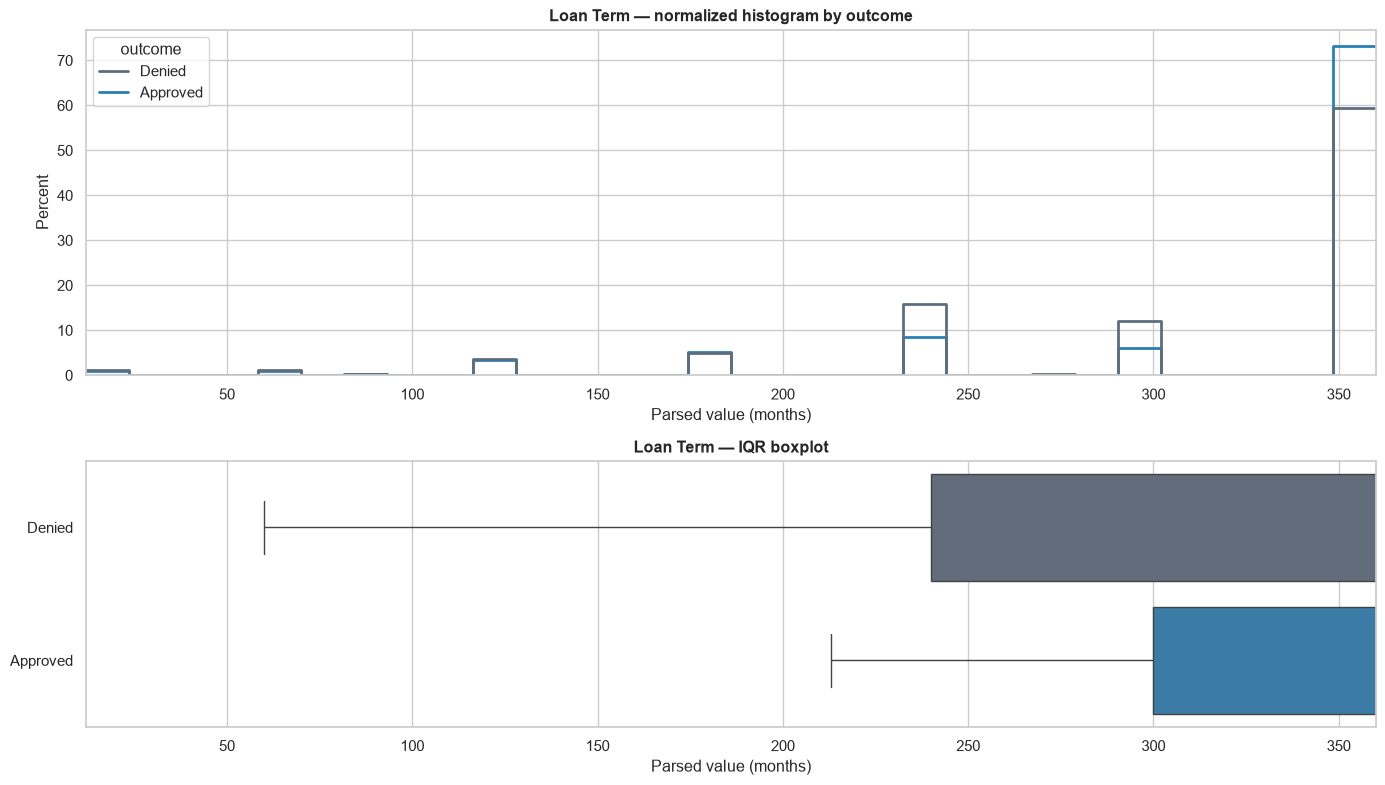

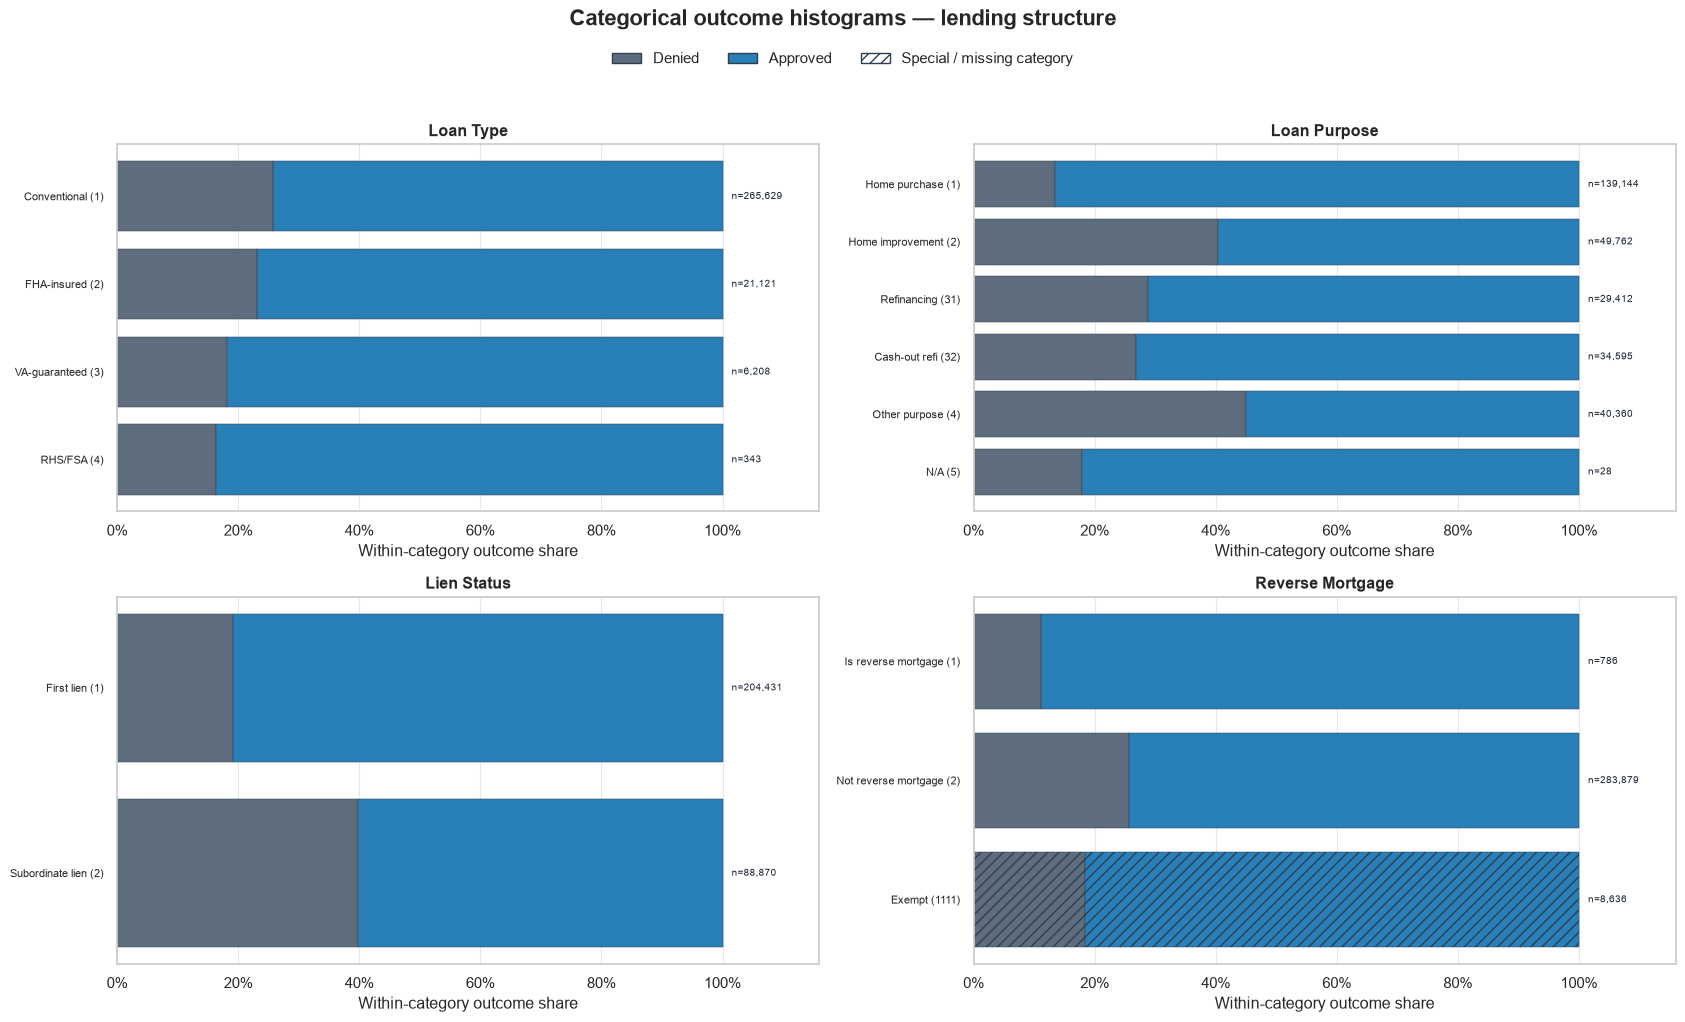

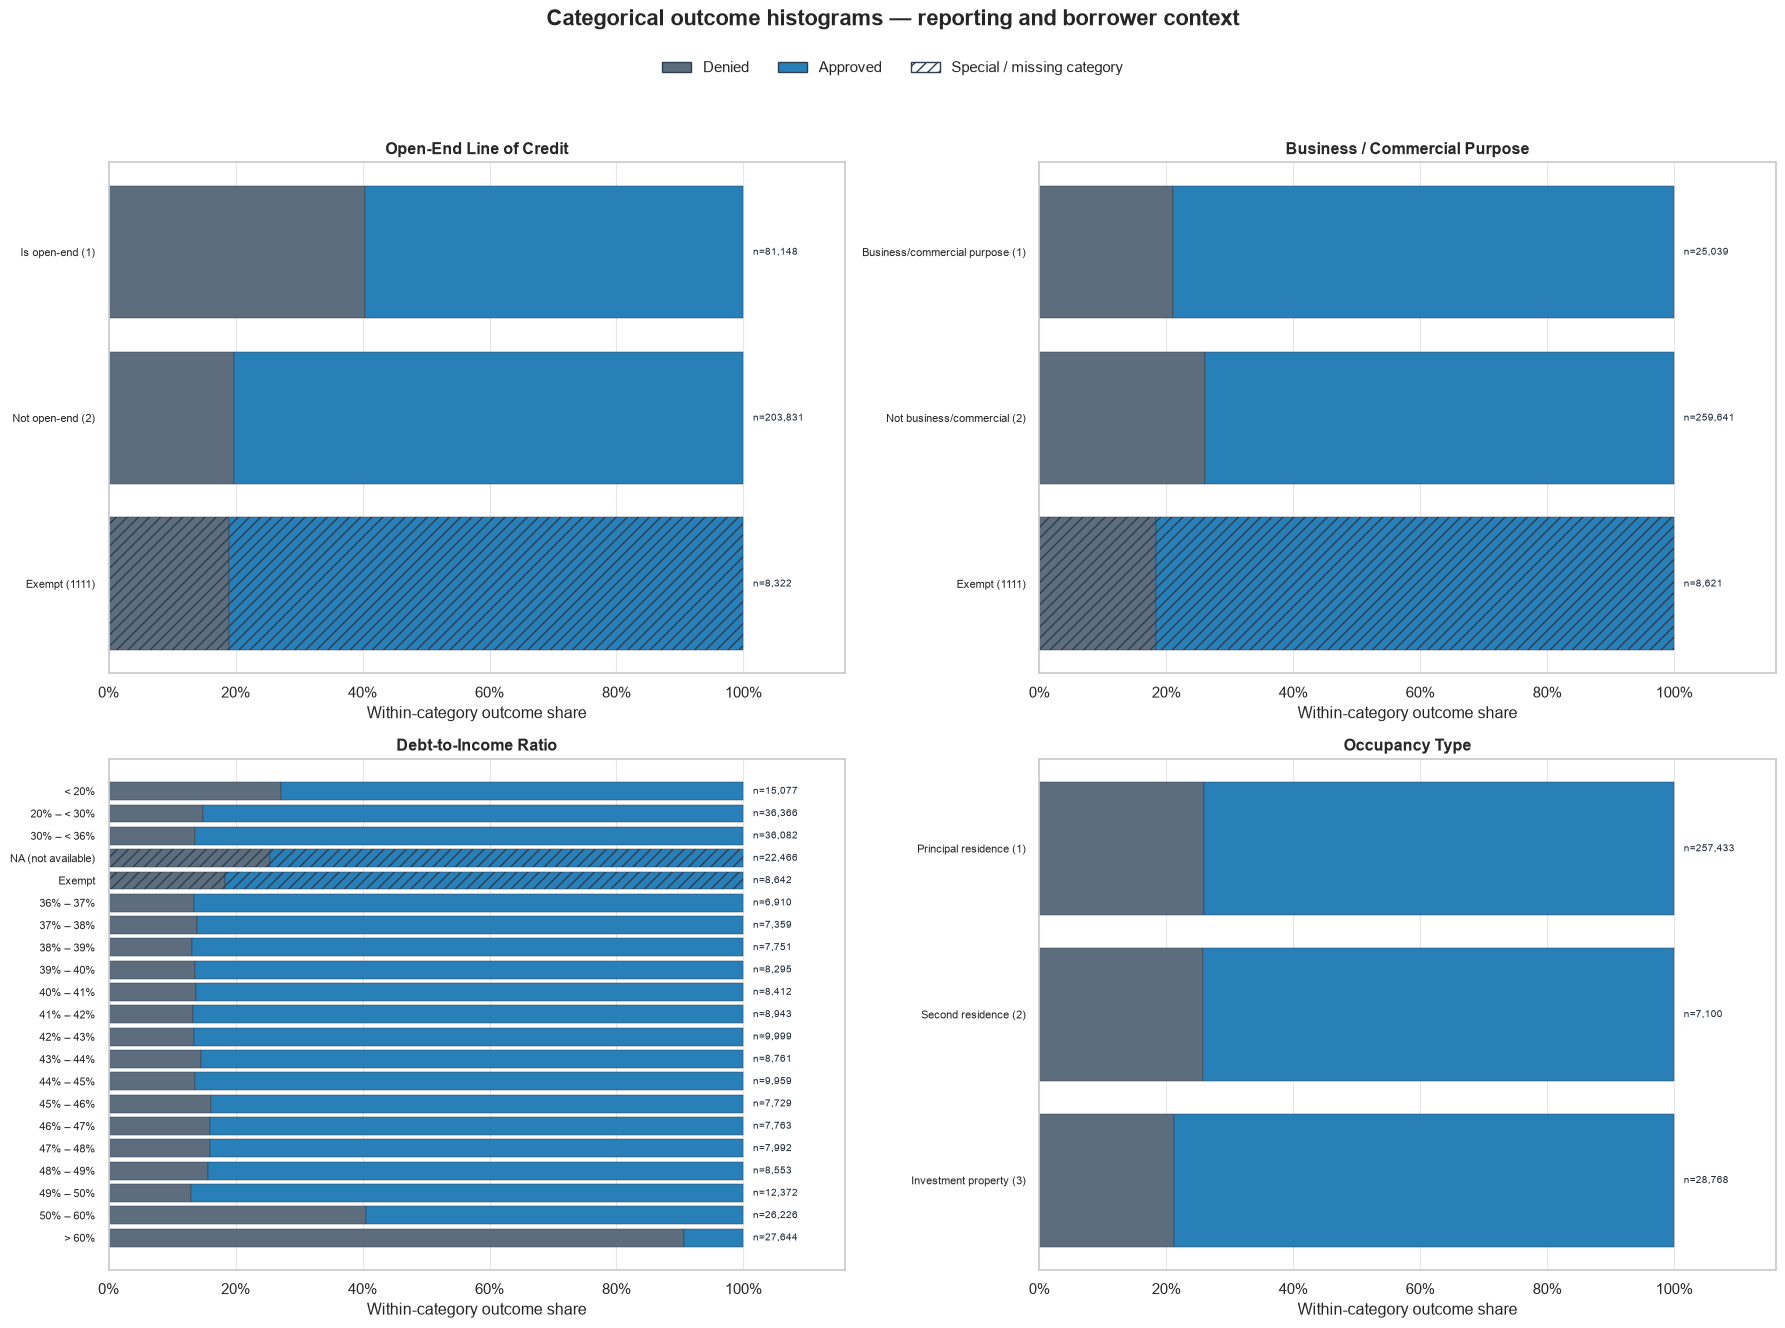

[RESULT] Numeric associations with approval outcome
            feature  pair_n spearman_rho
        loan_amount  293301      +0.1869
             income  272723      +0.1756
          loan_term  274648      +0.1024
loan_to_value_ratio  274681      +0.0810

[RESULT] Categorical associations with approval outcome
                       feature  pair_n cramers_v
          debt_to_income_ratio  293301    0.5168
                  loan_purpose  293301    0.2906
                   lien_status  293301    0.2167
       open-end_line_of_credit  293301    0.2116
business_or_commercial_purpose  293301    0.0431
              reverse_mortgage  293301    0.0330
                occupancy_type  293301    0.0323
                     loan_type  293301    0.0302


In [8]:
# EDA v2 staging — Task 03E: target-aware associations and distributions
from matplotlib.colors import Normalize
from matplotlib.ticker import MaxNLocator
from scipy.stats import chi2_contingency

assert len(eda_target) == len(eda_base)
eda_v2_outcome_label = eda_target.map({0: "Denied", 1: "Approved"}).astype("string")
_outcome_order = ["Denied", "Approved"]

def _fmt_title(feature):
    return EDA_V2_FEATURE_LABELS.get(feature, feature)

def _fmt_axis_label(feature):
    unit = EDA_V2_NUMERIC_UNITS.get(feature, "")
    return f"Parsed value ({unit})" if unit else "Parsed value"

def _eda_v2_compact_tick(value, _):
    magnitude = abs(value)
    if magnitude >= 1_000_000:
        return f"{value / 1_000_000:.1f}M"
    if magnitude >= 1_000:
        return f"{value / 1_000:.0f}K"
    return f"{value:,.0f}"

def _eda_v2_cramers_v(left, right):
    table = pd.crosstab(left, right, dropna=False)
    n = int(table.to_numpy().sum())
    if n <= 1 or min(table.shape) <= 1:
        return 0.0
    chi2 = chi2_contingency(table.to_numpy(), correction=False)[0]
    phi2 = chi2 / n
    rows, columns = table.shape
    corrected_phi2 = max(0.0, phi2 - ((columns - 1) * (rows - 1)) / (n - 1))
    corrected_rows = rows - ((rows - 1) ** 2) / (n - 1)
    corrected_columns = columns - ((columns - 1) ** 2) / (n - 1)
    denominator = min(corrected_columns - 1, corrected_rows - 1)
    return 0.0 if denominator <= 0 else float(np.sqrt(corrected_phi2 / denominator))

_numeric_target_rows = []
for feature in EDA_V2_NUMERIC_FEATURES:
    pair = pd.concat([eda_v2_numeric_before[feature], eda_target], axis=1).dropna()
    _numeric_target_rows.append({"feature": feature, "pair_n": len(pair), "spearman_rho": float(pair[feature].corr(pair["approved"], method="spearman"))})
eda_v2_target_numeric_association = pd.DataFrame(_numeric_target_rows).sort_values("spearman_rho", key=lambda s: s.abs())

_categorical_target_rows = []
for feature in EDA_V2_CATEGORICAL_FEATURES:
    _categorical_target_rows.append({"feature": feature, "pair_n": len(eda_base), "cramers_v": _eda_v2_cramers_v(eda_v2_categorical_before[feature], eda_v2_outcome_label)})
eda_v2_target_categorical_association = pd.DataFrame(_categorical_target_rows).sort_values("cramers_v")

eda_v2_target_association_figure, (_ax_numeric, _ax_categorical) = plt.subplots(1, 2, figsize=(16, 7), gridspec_kw={"width_ratios": [0.9, 1.3]})
_num_plot = eda_v2_target_numeric_association
_num_y = np.arange(len(_num_plot))
_num_colors = [EDA_V2_COLORS["after"] if value >= 0 else EDA_V2_DIVERGING_COLORS[0] for value in _num_plot["spearman_rho"]]
_ax_numeric.hlines(_num_y, 0, _num_plot["spearman_rho"], color=_num_colors, linewidth=3)
_ax_numeric.scatter(_num_plot["spearman_rho"], _num_y, color=_num_colors, s=90, zorder=3)
_ax_numeric.axvline(0, color=EDA_V2_COLORS["reference"], linestyle="--", linewidth=1.2)
_ax_numeric.set_yticks(_num_y, [_fmt_title(feature) for feature in _num_plot["feature"]])
_rho_limit = max(0.25, float(_num_plot["spearman_rho"].abs().max()) + 0.05)
_ax_numeric.set_xlim(-_rho_limit, _rho_limit)
_ax_numeric.set_xlabel("Signed Spearman ρ")
_ax_numeric.set_title("Numeric features vs approval outcome", fontweight="bold")
for y, value in zip(_num_y, _num_plot["spearman_rho"]):
    _ax_numeric.text(value + (0.012 if value >= 0 else -0.012), y, f"{value:+.3f}", va="center", ha="left" if value >= 0 else "right", fontsize=9)

_cat_plot = eda_v2_target_categorical_association
_cat_norm = Normalize(vmin=0, vmax=max(0.55, float(_cat_plot["cramers_v"].max())))
_cat_colors = [EDA_V2_ASSOCIATION_CMAP(_cat_norm(value)) for value in _cat_plot["cramers_v"]]
_cat_bars = _ax_categorical.barh([_fmt_title(feature) for feature in _cat_plot["feature"]], _cat_plot["cramers_v"], color=_cat_colors, edgecolor=EDA_V2_COLORS["reference"], linewidth=0.5)
_ax_categorical.set_xlim(0, max(0.55, float(_cat_plot["cramers_v"].max()) + 0.06))
_ax_categorical.set_xlabel("Bias-corrected Cramér's V")
_ax_categorical.set_title("Categorical features vs approval outcome", fontweight="bold")
for bar, value in zip(_cat_bars, _cat_plot["cramers_v"]):
    _ax_categorical.text(value + 0.008, bar.get_y() + bar.get_height() / 2, f"{value:.3f}", va="center", fontsize=9)
for axis in (_ax_numeric, _ax_categorical):
    axis.grid(True, axis="x", color=EDA_V2_COLORS["grid"], linewidth=0.8)
    axis.grid(False, axis="y")
eda_v2_target_association_figure.suptitle("Feature Associations with Mortgage Approval", fontsize=16, fontweight="bold")
eda_v2_target_association_figure.tight_layout(rect=(0, 0, 1, 0.94))
plt.show()

# Continuous numeric distributions: KDE and full Tukey boxplots are separate figures.
_continuous_features = ("income", "loan_amount", "loan_to_value_ratio")
eda_v2_target_continuous_figure, _continuous_axes = plt.subplots(1, len(_continuous_features), figsize=(18, 5.5))
eda_v2_target_boxplot_figure = plt.figure(figsize=(20, 5.5))
_boxplot_grid = eda_v2_target_boxplot_figure.add_gridspec(1, 4, width_ratios=[1, 1, 1, 0.72])
_boxplot_axes = np.array([eda_v2_target_boxplot_figure.add_subplot(_boxplot_grid[0, index]) for index in range(3)])
eda_v2_ltv_full_range_axis = eda_v2_target_boxplot_figure.add_subplot(_boxplot_grid[0, 3])
_eda_v2_flierprops = {
    "marker": "o",
    "markersize": 2.0,
    "markerfacecolor": EDA_V2_COLORS["reference"],
    "markeredgecolor": "none",
    "alpha": 0.35,
    "rasterized": True,
}
eda_v2_target_continuous_summary_rows = []
for column, feature in enumerate(_continuous_features):
    pair = pd.DataFrame({feature: eda_v2_numeric_before[feature], "outcome": eda_v2_outcome_label}).dropna()
    lower, upper = pair[feature].quantile([0.01, 0.99])
    central = pair[pair[feature].between(lower, upper)]
    for outcome in _outcome_order:
        values = central.loc[central["outcome"].eq(outcome), feature]
        sns.kdeplot(values, ax=_continuous_axes[column], color=EDA_V2_TARGET_COLORS[outcome], linewidth=2.2, linestyle="--" if outcome == "Denied" else "-", label=outcome, warn_singular=False)
    _continuous_axes[column].set_xlim(lower, upper)
    _continuous_axes[column].set_title(_fmt_title(feature), fontweight="bold")
    _continuous_axes[column].set_xlabel(_fmt_axis_label(feature))
    _continuous_axes[column].xaxis.set_major_formatter(FuncFormatter(lambda value, _: f"{value:,.0f}"))
    _continuous_axes[column].legend(frameon=False)
    sns.boxplot(data=pair, x=feature, y="outcome", order=_outcome_order, hue="outcome", hue_order=_outcome_order, palette=EDA_V2_TARGET_COLORS, whis=1.5, showfliers=True, flierprops=_eda_v2_flierprops, legend=False, ax=_boxplot_axes[column])
    if feature == "income":
        _boxplot_axes[column].set_xscale("symlog", linthresh=10)
        _boxplot_axes[column].set_xlim(0, pair[feature].max() * 1.05)
    elif feature == "loan_amount":
        _boxplot_axes[column].set_xscale("log")
    else:
        _boxplot_axes[column].set_xlim(0, max(120, upper * 1.1))
        sns.boxplot(data=pair, x=feature, y="outcome", order=_outcome_order, hue="outcome", hue_order=_outcome_order, palette=EDA_V2_TARGET_COLORS, whis=1.5, showfliers=True, flierprops=_eda_v2_flierprops, legend=False, ax=eda_v2_ltv_full_range_axis)
        eda_v2_ltv_full_range_axis.set_title("LTV — full range", fontweight="bold")
        eda_v2_ltv_full_range_axis.set_xlabel("Parsed value (%)")
        eda_v2_ltv_full_range_axis.set_ylabel("")
        eda_v2_ltv_full_range_axis.set_yticks([])
        eda_v2_ltv_full_range_axis.xaxis.set_major_locator(MaxNLocator(3))
        eda_v2_ltv_full_range_axis.xaxis.set_major_formatter(FuncFormatter(_eda_v2_compact_tick))
        eda_v2_ltv_full_range_axis.tick_params(axis="x", labelsize=8)
    _boxplot_axes[column].set_title(_fmt_title(feature), fontweight="bold")
    _boxplot_axes[column].set_xlabel(_fmt_axis_label(feature))
    _boxplot_axes[column].set_ylabel("Outcome" if column == 0 else "")
    eda_v2_target_continuous_summary_rows.append({"feature": feature, "observed_n": len(pair), "display_p01": lower, "display_p99": upper})
eda_v2_target_continuous_summary = pd.DataFrame(eda_v2_target_continuous_summary_rows)
eda_v2_target_continuous_figure.suptitle("Continuous feature KDE by approval outcome — P1–P99 display window", fontsize=16, fontweight="bold")
eda_v2_target_continuous_figure.tight_layout(rect=(0, 0, 1, 0.92))
eda_v2_target_boxplot_figure.suptitle("Boxplots for continuous features by approval outcome", fontsize=16, fontweight="bold")
eda_v2_target_boxplot_figure.tight_layout(rect=(0, 0, 1, 0.92))
plt.show()

# Loan term is discrete, so use a normalized histogram rather than KDE.
_term_pair = pd.DataFrame({"loan_term": eda_v2_numeric_before["loan_term"], "outcome": eda_v2_outcome_label}).dropna()
_term_lower, _term_upper = _term_pair["loan_term"].quantile([0.01, 0.99])
_term_central = _term_pair[_term_pair["loan_term"].between(_term_lower, _term_upper)]
eda_v2_target_term_figure, _term_axes = plt.subplots(2, 1, figsize=(14, 8), gridspec_kw={"height_ratios": [1.3, 1]})
sns.histplot(data=_term_central, x="loan_term", hue="outcome", hue_order=_outcome_order, palette=EDA_V2_TARGET_COLORS, stat="percent", common_norm=False, element="step", fill=False, bins=30, linewidth=2, ax=_term_axes[0])
_term_axes[0].set_xlim(_term_lower, _term_upper)
_term_axes[0].set_title("Loan Term — normalized histogram by outcome", fontweight="bold")
_term_axes[0].set_xlabel(_fmt_axis_label("loan_term"))
sns.boxplot(data=_term_pair, x="loan_term", y="outcome", order=_outcome_order, hue="outcome", hue_order=_outcome_order, palette=EDA_V2_TARGET_COLORS, showfliers=False, legend=False, ax=_term_axes[1])
_term_axes[1].set_xlim(_term_lower, _term_upper)
_term_axes[1].set_title("Loan Term — IQR boxplot", fontweight="bold")
_term_axes[1].set_xlabel(_fmt_axis_label("loan_term"))
_term_axes[1].set_ylabel("")
eda_v2_target_term_figure.tight_layout()
plt.show()

def _eda_v2_plot_target_category_group(features, title, figsize):
    figure, axes = plt.subplots(2, 2, figsize=figsize)
    for axis, feature in zip(axes.flat, features):
        values = eda_v2_categorical_before[feature]
        raw_order = [value for value in EDA_V2_CATEGORY_LABELS[feature] if value in set(values)]
        if values.eq("MISSING").any():
            raw_order.append("MISSING")
        table = pd.crosstab(values, eda_v2_outcome_label).reindex(index=raw_order, columns=_outcome_order, fill_value=0)
        shares = table.div(table.sum(axis=1), axis=0).mul(100)
        y = np.arange(len(table))
        denied = axis.barh(y, shares["Denied"], color=EDA_V2_TARGET_COLORS["Denied"], label="Denied")
        approved = axis.barh(y, shares["Approved"], left=shares["Denied"], color=EDA_V2_TARGET_COLORS["Approved"], label="Approved")
        special_tokens = EDA_V2_CATEGORICAL_SPECIAL_TOKENS[feature] | {"MISSING"}
        for raw_value, denied_patch, approved_patch in zip(raw_order, denied, approved):
            if raw_value in special_tokens:
                denied_patch.set_hatch("///")
                approved_patch.set_hatch("///")
            denied_patch.set_edgecolor(EDA_V2_COLORS["reference"])
            approved_patch.set_edgecolor(EDA_V2_COLORS["reference"])
            denied_patch.set_linewidth(0.35)
            approved_patch.set_linewidth(0.35)
        axis.set_yticks(y, [EDA_V2_CATEGORY_LABELS[feature].get(value, value) for value in raw_order], fontsize=8)
        axis.invert_yaxis()
        axis.set_xlim(0, 116)
        axis.xaxis.set_major_formatter(PercentFormatter(100))
        axis.set_title(_fmt_title(feature), fontweight="bold")
        axis.set_xlabel("Within-category outcome share")
        for position, count in enumerate(table.sum(axis=1)):
            axis.text(101.5, position, f"n={int(count):,}", va="center", fontsize=7.5, color=EDA_V2_COLORS["text"])
        axis.grid(True, axis="x", color=EDA_V2_COLORS["grid"], linewidth=0.8)
        axis.grid(False, axis="y")
    handles = [Patch(facecolor=EDA_V2_TARGET_COLORS[outcome], edgecolor=EDA_V2_COLORS["reference"], label=outcome) for outcome in _outcome_order]
    handles.append(Patch(facecolor="white", edgecolor=EDA_V2_COLORS["reference"], hatch="///", label="Special / missing category"))
    figure.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, 0.99), ncol=3, frameon=False)
    figure.suptitle(title, fontsize=16, fontweight="bold", y=1.02)
    figure.tight_layout(rect=(0, 0, 1, 0.96))
    plt.show()
    return figure, axes

eda_v2_target_categorical_figure_a, eda_v2_target_categorical_axes_a = _eda_v2_plot_target_category_group(EDA_V2_CATEGORICAL_FEATURES[:4], "Categorical outcome histograms — lending structure", (17, 10))
eda_v2_target_categorical_figure_b, eda_v2_target_categorical_axes_b = _eda_v2_plot_target_category_group(EDA_V2_CATEGORICAL_FEATURES[4:], "Categorical outcome histograms — reporting and borrower context", (18, 13))

print("[RESULT] Numeric associations with approval outcome")
print(eda_v2_target_numeric_association.sort_values("spearman_rho", key=lambda s: s.abs(), ascending=False).to_string(index=False, formatters={"spearman_rho": "{:+.4f}".format}))
print("\n[RESULT] Categorical associations with approval outcome")
print(eda_v2_target_categorical_association.sort_values("cramers_v", ascending=False).to_string(index=False, formatters={"cramers_v": "{:.4f}".format}))

del _numeric_target_rows, _categorical_target_rows, _num_plot, _num_y, _num_colors, _rho_limit, _cat_plot, _cat_norm, _cat_colors, _cat_bars, _continuous_features, _term_pair, _term_central, _term_lower, _term_upper, _outcome_order, _eda_v2_flierprops


**Figures 3–8 — Outcome-aware EDA.**  
Figure 3 ranks univariate association with approval: signed Spearman ρ for numeric features and bias-corrected Cramér's V for categorical features. Figure 4 shows KDE for continuous variables within the P1–P99 display window. Figure 5 is a dedicated standard Tukey boxplot figure for Income, Loan Amount and LTV: boxes show Q1–Q3, center lines show medians, whiskers use 1.5×IQR and outlier points remain visible. Income uses symlog, Loan Amount uses log and LTV remains linear; a fourth LTV full-range panel preserves extreme-value visibility while the primary LTV panel keeps the box readable. Figure 6 uses a normalized histogram plus boxplot for discrete Loan Term. Figures 7–8 use 100% within-category histograms with record counts; special states remain separate and hatched. These comparisons are descriptive, not causal or model importance estimates.

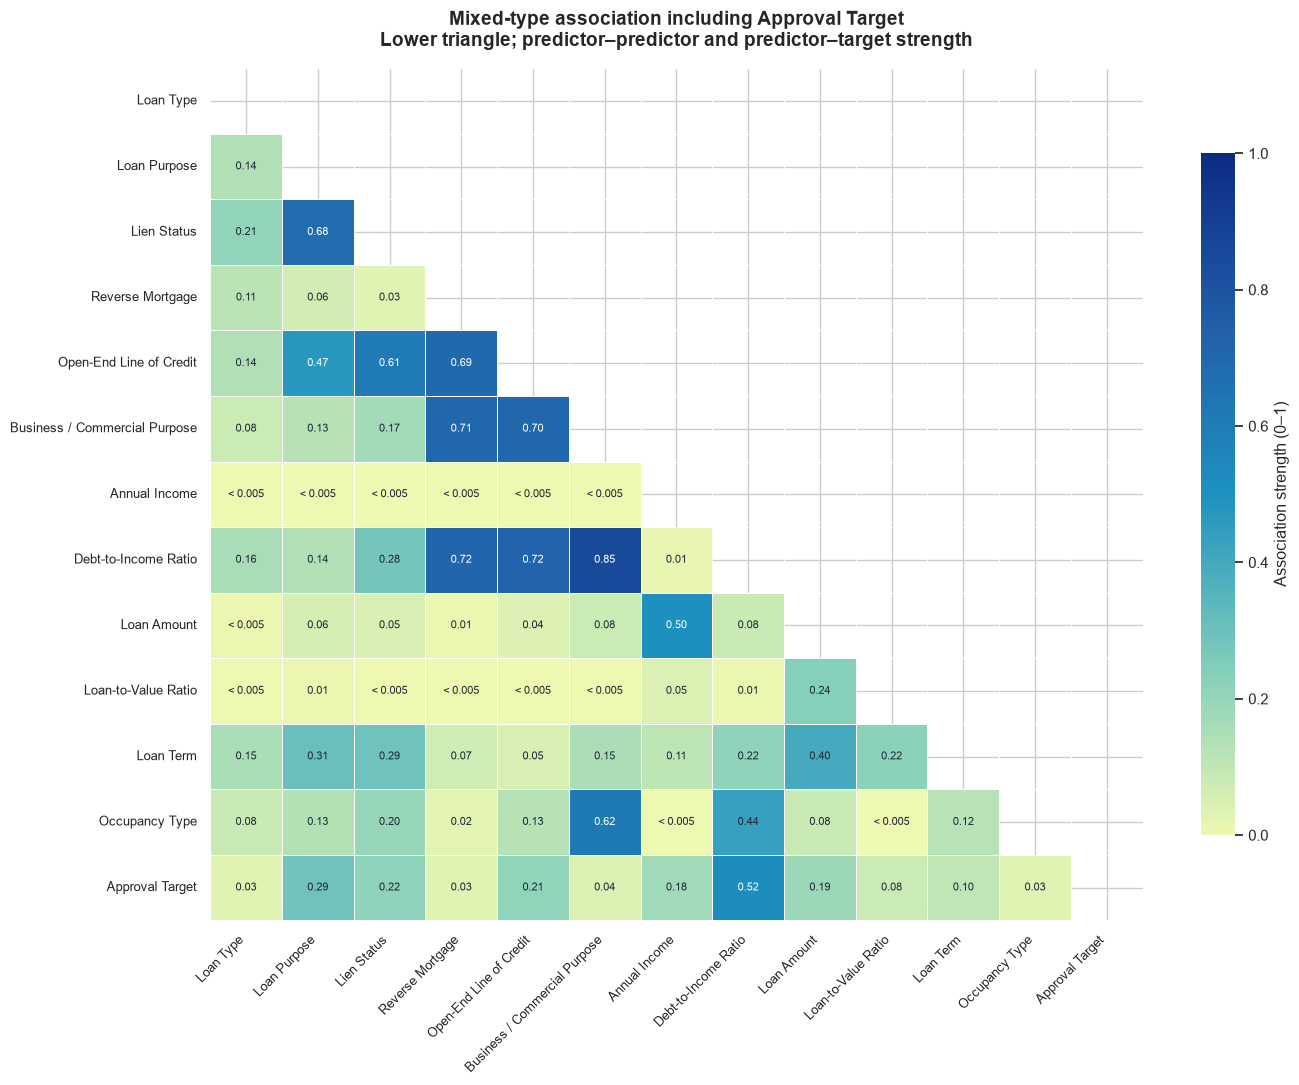

[RESULT] Strongest mixed-type associations
                          left                          right                               method  pair_n association_strength
business_or_commercial_purpose           debt_to_income_ratio             bias_corrected_cramers_v  293301               0.8493
       open-end_line_of_credit           debt_to_income_ratio             bias_corrected_cramers_v  293301               0.7226
              reverse_mortgage           debt_to_income_ratio             bias_corrected_cramers_v  293301               0.7173
              reverse_mortgage business_or_commercial_purpose             bias_corrected_cramers_v  293301               0.7060
       open-end_line_of_credit business_or_commercial_purpose             bias_corrected_cramers_v  293301               0.7037
              reverse_mortgage        open-end_line_of_credit             bias_corrected_cramers_v  293301               0.6950
                  loan_purpose                    lien_status

In [9]:
# EDA v2 staging — Task 03E: mixed-type association
from scipy.stats import chi2_contingency


def _eda_v2_cramers_v(left, right):
    table = pd.crosstab(left, right, dropna=False)
    n = int(table.to_numpy().sum())
    if n <= 1 or min(table.shape) <= 1:
        return 0.0
    chi2 = chi2_contingency(table.to_numpy(), correction=False)[0]
    phi2 = chi2 / n
    rows, columns = table.shape
    corrected_phi2 = max(
        0.0, phi2 - ((columns - 1) * (rows - 1)) / (n - 1)
    )
    corrected_rows = rows - ((rows - 1) ** 2) / (n - 1)
    corrected_columns = columns - ((columns - 1) ** 2) / (n - 1)
    denominator = min(corrected_columns - 1, corrected_rows - 1)
    return 0.0 if denominator <= 0 else float(
        np.sqrt(corrected_phi2 / denominator)
    )


def _eda_v2_correlation_ratio(categories, values):
    pair = pd.DataFrame(
        {"category": categories, "value": values}
    ).dropna()
    if pair.empty or pair["category"].nunique() <= 1:
        return 0.0
    numeric = pair["value"].to_numpy(dtype=float)
    grand_mean = float(numeric.mean())
    total = float(np.square(numeric - grand_mean).sum())
    if total <= 0:
        return 0.0
    grouped = pair.groupby("category", observed=True)["value"].agg(
        ["count", "mean"]
    )
    between = float(
        (
            grouped["count"]
            * np.square(grouped["mean"] - grand_mean)
        ).sum()
    )
    return float(np.sqrt(between / total))


eda_v2_association = pd.DataFrame(
    np.eye(len(EDA_V2_FEATURES)),
    index=EDA_V2_FEATURES,
    columns=EDA_V2_FEATURES,
)
eda_v2_association_rows = []
_numeric_set = set(EDA_V2_NUMERIC_FEATURES)

for left_index, left in enumerate(EDA_V2_FEATURES):
    for right in EDA_V2_FEATURES[left_index + 1 :]:
        left_numeric = left in _numeric_set
        right_numeric = right in _numeric_set
        if left_numeric and right_numeric:
            pair = pd.concat(
                [
                    eda_v2_numeric_before[left],
                    eda_v2_numeric_before[right],
                ],
                axis=1,
            ).dropna()
            value = abs(float(pair[left].corr(pair[right], method="spearman")))
            method = "abs_spearman"
        elif not left_numeric and not right_numeric:
            pair = pd.concat(
                [
                    eda_v2_categorical_before[left],
                    eda_v2_categorical_before[right],
                ],
                axis=1,
            ).dropna()
            value = _eda_v2_cramers_v(pair[left], pair[right])
            method = "bias_corrected_cramers_v"
        else:
            numeric_feature = left if left_numeric else right
            categorical_feature = right if left_numeric else left
            pair = pd.concat(
                [
                    eda_v2_numeric_before[numeric_feature],
                    eda_v2_categorical_before[categorical_feature],
                ],
                axis=1,
            ).dropna()
            value = _eda_v2_correlation_ratio(
                pair[categorical_feature], pair[numeric_feature]
            )
            method = "correlation_ratio_eta"
        eda_v2_association.loc[left, right] = value
        eda_v2_association.loc[right, left] = value
        eda_v2_association_rows.append(
            {
                "left": left,
                "right": right,
                "method": method,
                "pair_n": len(pair),
                "association_strength": value,
            }
        )

_target_key = "approval_outcome"
eda_v2_association[_target_key] = np.nan
eda_v2_association.loc[_target_key] = np.nan
eda_v2_association.loc[_target_key, _target_key] = 1.0
for feature in EDA_V2_FEATURES:
    if feature in _numeric_set:
        target_row = eda_v2_target_numeric_association.set_index("feature").loc[feature]
        value = abs(float(target_row["spearman_rho"]))
        method = "abs_spearman_with_target"
    else:
        target_row = eda_v2_target_categorical_association.set_index("feature").loc[feature]
        value = float(target_row["cramers_v"])
        method = "bias_corrected_cramers_v_with_target"
    eda_v2_association.loc[feature, _target_key] = value
    eda_v2_association.loc[_target_key, feature] = value
    eda_v2_association_rows.append(
        {
            "left": feature,
            "right": _target_key,
            "method": method,
            "pair_n": int(target_row["pair_n"]),
            "association_strength": value,
        }
    )

eda_v2_association_pairs = (
    pd.DataFrame(eda_v2_association_rows)
    .sort_values(
        ["association_strength", "left", "right"],
        ascending=[False, True, True],
    )
    .reset_index(drop=True)
)
assert eda_v2_association.shape == (13, 13)
assert len(eda_v2_association_pairs) == 78
assert np.isfinite(eda_v2_association.to_numpy()).all()
assert np.allclose(
    eda_v2_association.to_numpy(), eda_v2_association.to_numpy().T
)

_mask = np.triu(
    np.ones_like(eda_v2_association, dtype=bool),
    k=0,
)
_association_labels = eda_v2_association.map(
    lambda value: "< 0.005" if 0 < value < 0.005 else f"{value:.2f}"
)
eda_v2_association_figure, eda_v2_association_axis = plt.subplots(
    figsize=(14, 11)
)
sns.heatmap(
    eda_v2_association,
    mask=_mask,
    cmap=EDA_V2_ASSOCIATION_CMAP,
    vmin=0,
    vmax=1,
    annot=_association_labels,
    fmt="",
    annot_kws={"fontsize": 8},
    linewidths=0.5,
    linecolor="white",
    cbar_kws={"label": "Association strength (0–1)", "shrink": 0.8},
    ax=eda_v2_association_axis,
)
for text, value in zip(
    eda_v2_association_axis.texts, eda_v2_association.to_numpy()[~_mask]
):
    text.set_color("white" if value >= 0.45 else EDA_V2_COLORS["text"])
eda_v2_association_axis.set_title(
    "Mixed-type association including Approval Target\n"
    "Lower triangle; predictor–predictor and predictor–target strength",
    fontsize=14,
    fontweight="bold",
    pad=16,
)
eda_v2_association_axis.set_xlabel("")
eda_v2_association_axis.set_ylabel("")
_association_display_labels = {**EDA_V2_FEATURE_LABELS, _target_key: "Approval Target"}
_hm_labels = [_association_display_labels.get(t.get_text(), t.get_text())
               for t in eda_v2_association_axis.get_xticklabels()]
eda_v2_association_axis.set_xticklabels(
    _hm_labels,
    rotation=45,
    ha="right",
    fontsize=9,
)
_hm_ylabels = [_association_display_labels.get(t.get_text(), t.get_text())
               for t in eda_v2_association_axis.get_yticklabels()]
eda_v2_association_axis.set_yticklabels(
    _hm_ylabels,
    rotation=0,
    fontsize=9,
)
del _hm_labels, _hm_ylabels, _association_display_labels
eda_v2_association_figure.tight_layout()
plt.show()

print("[RESULT] Strongest mixed-type associations")
print(
    eda_v2_association_pairs.head(10).to_string(
        index=False,
        formatters={"association_strength": "{:.4f}".format},
    )
)
del _numeric_set, _mask, _association_labels, _target_key, target_row


**Figure 9 — Mixed-type association heatmap including Approval Target.**  
Population: eligible Dataset B cohort, *n* = 293,301. Stage: parsed `eda_base` plus aligned binary `eda_target`, before model preprocessing. The matrix contains 12 predictors and Approval Target. Numeric–numeric and numeric–target cells use absolute Spearman ρ; numeric–categorical cells use correlation ratio η; categorical–categorical and categorical–target cells use bias-corrected Cramér's V. The sequential yellow–green–blue scale encodes unsigned association strength; signed target direction remains available in Figure 3. Values below 0.005 are printed as `<0.005`. *Caveat:* metrics differ by variable type, so compare strength—not causal meaning—across cells.

In [10]:
# EDA v2 staging — Task 03F: summary findings and acceptance gate
_top_association = eda_v2_association_pairs.iloc[0]
_most_special = (
    eda_v2_coverage_audit.sort_values(
        ["special_n", "feature"], ascending=[False, True]
    )
    .iloc[0]
)
_largest_tail = (
    eda_v2_numeric_summary.sort_values(
        ["iqr_outlier_n", "feature"], ascending=[False, True]
    )
    .iloc[0]
)
_top_target_numeric = eda_v2_target_numeric_association.iloc[
    eda_v2_target_numeric_association["spearman_rho"].abs().argmax()
]
_top_target_categorical = eda_v2_target_categorical_association.iloc[-1]

eda_v2_task_03_findings = pd.DataFrame(
    [
        {
            "finding": "strongest_numeric_target_association",
            "result": _top_target_numeric["feature"],
            "value": float(_top_target_numeric["spearman_rho"]),
            "context": "signed Spearman rho with approval",
        },
        {
            "finding": "strongest_categorical_target_association",
            "result": _top_target_categorical["feature"],
            "value": float(_top_target_categorical["cramers_v"]),
            "context": "bias-corrected Cramer's V with approval",
        },
        {
            "finding": "largest_special_state_feature",
            "result": _most_special["feature"],
            "value": int(_most_special["special_n"]),
            "context": f"{_most_special['special_pct']:.2f}% of parsed cohort",
        },
        {
            "finding": "strongest_mixed_type_association",
            "result": f"{_top_association['left']} × {_top_association['right']}",
            "value": float(_top_association["association_strength"]),
            "context": (
                f"{_top_association['method']}; "
                f"pair_n={int(_top_association['pair_n']):,}"
            ),
        },
        {
            "finding": "largest_iqr_tail_count",
            "result": _largest_tail["feature"],
            "value": int(_largest_tail["iqr_outlier_n"]),
            "context": "1.5×IQR descriptive flag; values are retained",
        },
    ]
)

assert eda_v2_before.equals(eda_base)
assert len(eda_target) == len(eda_base)
assert set(eda_target.unique()) == {0, 1}
assert eda_v2_numeric_before.shape == (
    len(eda_base), len(EDA_V2_NUMERIC_FEATURES)
)
assert eda_v2_categorical_before.shape == (
    len(eda_base), len(EDA_V2_CATEGORICAL_FEATURES)
)
assert not any(
    name in globals()
    for name in (
        "eda_v2_imputer",
        "eda_v2_encoder",
        "eda_v2_scaler",
        "eda_v2_log_transformer",
        "eda_v2_processed",
    )
)

EDA_V2_TASK_03_SUMMARY = {
    "population_rows": len(eda_base),
    "source_dataframe": "eda_base",
    "coverage_features": len(eda_v2_coverage_audit),
    "numeric_features": len(eda_v2_numeric_summary),
    "categorical_frequency_rows": len(eda_v2_categorical_frequency),
    "association_pairs": len(eda_v2_association_pairs),
    "target_numeric_associations": len(eda_v2_target_numeric_association),
    "target_categorical_associations": len(eda_v2_target_categorical_association),
    "imputation_used": False,
    "value_status_channels_created": False,
    "encoding_used": False,
    "log_transform_used": False,
    "scaling_used": False,
    "eda_base_unchanged": True,
}

print("[RESULT] Part A summary findings")
print(eda_v2_task_03_findings.to_string(index=False))
print("\n[PASS] Part A uses eda_base plus aligned eda_target and preserves parsed feature values.")
print("[PASS] No imputation, value/status construction, encoding, log, or scaling was applied.")
EDA_V2_TASK_03_SUMMARY

del _top_association, _most_special, _largest_tail, _top_target_numeric, _top_target_categorical


[RESULT] Part A summary findings
                                 finding                                                result        value                                       context
    strongest_numeric_target_association                                           loan_amount     0.186857             signed Spearman rho with approval
strongest_categorical_target_association                                  debt_to_income_ratio     0.516846       bias-corrected Cramer's V with approval
           largest_special_state_feature                                  debt_to_income_ratio 31108.000000                       10.61% of parsed cohort
        strongest_mixed_type_association business_or_commercial_purpose × debt_to_income_ratio     0.849313      bias_corrected_cramers_v; pair_n=293,301
                  largest_iqr_tail_count                                             loan_term 33728.000000 1.5×IQR descriptive flag; values are retained

[PASS] Part A uses eda_base plus aligned e

## Part B — EDA-only semantic post-preprocessing view

`eda_processed` là representation 16 cột phục vụ trực quan hóa và so sánh trong notebook. Numeric medians được tính trên toàn bộ eligible cohort chỉ để tạo placeholder hiển thị; đây **không phải** Train-fitted production preprocessing và không được dùng làm bằng chứng cho model pipeline.

Phần này giữ riêng value/status để `NA`, `Exempt` và `MISSING` không bị diễn giải như giá trị numeric quan sát. Không tạo OHE 66 cột, không `log1p` và không scaling.

### Semantic view and schema audit


In [11]:
# EDA v2 staging — Task 04A: build the 16-column semantic view
assert "eda_base" in globals(), "Run EDA v2 Tasks 01–02 first."
assert tuple(eda_base.columns) == EDA_V2_FEATURES

_eda_v2_base_before_task_04 = eda_base.copy(deep=True)
EDA_V2_VALUE_COLUMNS = tuple(
    f"{feature}_value" for feature in EDA_V2_NUMERIC_FEATURES
)
EDA_V2_STATUS_COLUMNS = tuple(
    f"{feature}_status" for feature in EDA_V2_NUMERIC_FEATURES
)
EDA_V2_SEMANTIC_COLUMNS = tuple(
    output_column
    for feature in EDA_V2_FEATURES
    for output_column in (
        (f"{feature}_value", f"{feature}_status")
        if feature in EDA_V2_NUMERIC_FEATURES
        else (feature,)
    )
)
EDA_V2_STATUS_LEVELS = {
    "income": ("OBSERVED", "NA", "MISSING"),
    "loan_amount": ("OBSERVED", "MISSING"),
    "loan_to_value_ratio": ("OBSERVED", "NA", "Exempt", "MISSING"),
    "loan_term": ("OBSERVED", "NA", "Exempt", "MISSING"),
}

_eda_v2_processed_columns = {}
_eda_v2_numeric_preprocessing_rows = []

for feature in EDA_V2_FEATURES:
    if feature not in EDA_V2_NUMERIC_FEATURES:
        _eda_v2_processed_columns[feature] = eda_base[feature].copy(deep=True)
        continue

    raw_values = eda_base[feature]
    special_tokens = EDA_V2_NUMERIC_SPECIAL_TOKENS[feature]
    non_observed_tokens = special_tokens | {"MISSING"}
    observed_mask = ~raw_values.isin(non_observed_tokens)
    observed_values = pd.to_numeric(
        raw_values.loc[observed_mask],
        errors="raise",
    ).astype("float64")
    assert len(observed_values) > 0
    median_value = float(observed_values.median())

    status = raw_values.map(
        lambda value: (
            value
            if isinstance(value, str) and value in non_observed_tokens
            else "OBSERVED"
        )
    ).astype("string")
    assert status.isin(EDA_V2_STATUS_LEVELS[feature]).all()

    value_channel = pd.to_numeric(
        raw_values.mask(~observed_mask),
        errors="coerce",
    ).astype("float64")
    value_channel = value_channel.fillna(median_value)
    assert np.isfinite(value_channel.to_numpy()).all()

    _eda_v2_processed_columns[f"{feature}_value"] = value_channel
    _eda_v2_processed_columns[f"{feature}_status"] = status
    _eda_v2_numeric_preprocessing_rows.append(
        {
            "feature": feature,
            "observed_n": int(status.eq("OBSERVED").sum()),
            "NA_n": int(status.eq("NA").sum()),
            "Exempt_n": int(status.eq("Exempt").sum()),
            "MISSING_n": int(status.eq("MISSING").sum()),
            "median_placeholder": median_value,
            "placeholder_n": int(status.ne("OBSERVED").sum()),
        }
    )

eda_processed = pd.DataFrame(
    _eda_v2_processed_columns,
    index=eda_base.index,
).loc[:, EDA_V2_SEMANTIC_COLUMNS].copy()

eda_v2_numeric_preprocessing_audit = pd.DataFrame(
    _eda_v2_numeric_preprocessing_rows
)
print("[DATA QUALITY] EDA-only numeric placeholder audit")
print(
    eda_v2_numeric_preprocessing_audit.to_string(
        index=False,
        formatters={"median_placeholder": "{:,.4f}".format},
    )
)


[DATA QUALITY] EDA-only numeric placeholder audit
            feature  observed_n  NA_n  Exempt_n  MISSING_n median_placeholder  placeholder_n
             income      272723 20578         0          0           120.0000          20578
        loan_amount      293301     0         0          0       205,000.0000              0
loan_to_value_ratio      274681  9978      8642          0            74.9900          18620
          loan_term      274648 10360      8293          0           360.0000          18653


In [12]:
# EDA v2 staging — Task 04B: semantic-view acceptance gate
assert eda_base.equals(_eda_v2_base_before_task_04)
assert tuple(eda_processed.columns) == EDA_V2_SEMANTIC_COLUMNS
assert eda_processed.shape == (len(eda_base), 16)
assert len(EDA_V2_VALUE_COLUMNS) == 4
assert len(EDA_V2_STATUS_COLUMNS) == 4
assert len(EDA_V2_CATEGORICAL_FEATURES) == 8
assert set(EDA_V2_VALUE_COLUMNS).issubset(eda_processed.columns)
assert set(EDA_V2_STATUS_COLUMNS).issubset(eda_processed.columns)
assert set(EDA_V2_CATEGORICAL_FEATURES).issubset(eda_processed.columns)
assert np.isfinite(
    eda_processed.loc[:, EDA_V2_VALUE_COLUMNS].to_numpy(dtype="float64")
).all()

for feature in EDA_V2_NUMERIC_FEATURES:
    status_column = f"{feature}_status"
    value_column = f"{feature}_value"
    observed_mask = eda_processed[status_column].eq("OBSERVED")
    original_observed = pd.to_numeric(
        eda_base.loc[observed_mask, feature],
        errors="raise",
    ).astype("float64")
    pd.testing.assert_series_equal(
        eda_processed.loc[observed_mask, value_column],
        original_observed,
        check_names=False,
    )
    audit_row = (
        eda_v2_numeric_preprocessing_audit
        .set_index("feature")
        .loc[feature]
    )
    placeholder_mask = ~observed_mask
    assert int(placeholder_mask.sum()) == int(audit_row["placeholder_n"])
    if placeholder_mask.any():
        assert eda_processed.loc[
            placeholder_mask, value_column
        ].eq(float(audit_row["median_placeholder"])).all()

eda_v2_semantic_schema_audit = pd.DataFrame(
    [
        {
            "feature_group": "numeric_value",
            "column_count": len(EDA_V2_VALUE_COLUMNS),
            "columns": ", ".join(EDA_V2_VALUE_COLUMNS),
            "finite": True,
        },
        {
            "feature_group": "numeric_status",
            "column_count": len(EDA_V2_STATUS_COLUMNS),
            "columns": ", ".join(EDA_V2_STATUS_COLUMNS),
            "finite": "not_applicable",
        },
        {
            "feature_group": "categorical",
            "column_count": len(EDA_V2_CATEGORICAL_FEATURES),
            "columns": ", ".join(EDA_V2_CATEGORICAL_FEATURES),
            "finite": "not_applicable",
        },
    ]
)

EDA_V2_TASK_04_SUMMARY = {
    "view": "eda_processed",
    "scope": "full_eligible_cohort_eda_only",
    "rows": len(eda_processed),
    "columns": eda_processed.shape[1],
    "numeric_value_columns": len(EDA_V2_VALUE_COLUMNS),
    "numeric_status_columns": len(EDA_V2_STATUS_COLUMNS),
    "categorical_columns": len(EDA_V2_CATEGORICAL_FEATURES),
    "placeholder_cells_across_numeric_features": int(
        eda_v2_numeric_preprocessing_audit["placeholder_n"].sum()
    ),
    "finite_numeric_values": True,
    "train_fitted_production_pipeline": False,
    "ohe_created": False,
    "log1p_created": False,
    "scaling_created": False,
    "eda_base_unchanged": True,
}

print("[DATA QUALITY] EDA semantic schema")
print(eda_v2_semantic_schema_audit.to_string(index=False))
print(
    "\n[PASS] eda_processed contains 4 numeric value + "
    "4 numeric status + 8 categorical columns."
)
print(
    "[LIMITATION] Medians are full-cohort EDA placeholders, "
    "not Train-fitted production state."
)
print("[PASS] No OHE, log1p, or scaling was created.")
EDA_V2_TASK_04_SUMMARY

del (
    _eda_v2_base_before_task_04,
    _eda_v2_processed_columns,
    _eda_v2_numeric_preprocessing_rows,
)


[DATA QUALITY] EDA semantic schema
 feature_group  column_count                                                                                                                                               columns         finite
 numeric_value             4                                                                           income_value, loan_amount_value, loan_to_value_ratio_value, loan_term_value           True
numeric_status             4                                                                       income_status, loan_amount_status, loan_to_value_ratio_status, loan_term_status not_applicable
   categorical             8 loan_type, loan_purpose, lien_status, reverse_mortgage, open-end_line_of_credit, business_or_commercial_purpose, debt_to_income_ratio, occupancy_type not_applicable

[PASS] eda_processed contains 4 numeric value + 4 numeric status + 8 categorical columns.
[LIMITATION] Medians are full-cohort EDA placeholders, not Train-fitted production state.
[PASS] N

### ECDF and status-preservation evidence

Phần này chỉ so sánh các biến đổi thực sự đã được áp dụng: negative income được parser đưa về 0; numeric special states nhận median placeholder trong value channel nhưng vẫn giữ status; tám categorical features không đổi; schema chuyển từ 12 parsed columns sang 16 semantic columns.

Không có biểu đồ `log1p` hoặc OHE vì hai bước đó không được tạo trong EDA view hiện tại.


In [13]:
# EDA v2 staging — Task 05A: build before/after comparison data
assert "eda_base" in globals()
assert "eda_processed" in globals()

_eda_v2_base_before_task_05 = eda_base.copy(deep=True)
_eda_v2_processed_before_task_05 = eda_processed.copy(deep=True)

_income_parser_audit = (
    eda_v2_parser_audit.set_index("feature").loc["income"]
)
eda_v2_parser_change_comparison = pd.DataFrame(
    [
        {
            "transformation": "negative_income_to_zero",
            "before_n": int(_income_parser_audit["negative_income_to_zero_n"]),
            "after_n": int(
                sum(
                    isinstance(value, (int, float)) and value < 0
                    for value in eda_base["income"]
                )
            ),
            "preserved_in_status": "not_applicable",
        }
    ]
)

eda_v2_numeric_before_after_rows = []
eda_v2_status_preservation_rows = []
for feature in EDA_V2_NUMERIC_FEATURES:
    before_values = eda_v2_numeric_before[feature].dropna()
    value_column = f"{feature}_value"
    status_column = f"{feature}_status"
    after_values = eda_processed[value_column]
    statuses = eda_processed[status_column]
    audit = (
        eda_v2_numeric_preprocessing_audit
        .set_index("feature")
        .loc[feature]
    )
    observed_mask = statuses.eq("OBSERVED")
    unchanged_observed = np.array_equal(
        after_values.loc[observed_mask].to_numpy(),
        before_values.to_numpy(),
    )
    eda_v2_numeric_before_after_rows.append(
        {
            "feature": feature,
            "before_observed_n": len(before_values),
            "after_value_n": len(after_values),
            "placeholder_n": int(audit["placeholder_n"]),
            "placeholder_median": float(audit["median_placeholder"]),
            "before_median": float(before_values.median()),
            "after_median": float(after_values.median()),
            "observed_values_unchanged": bool(unchanged_observed),
        }
    )

    allowed_levels = EDA_V2_STATUS_LEVELS[feature]
    for status_level in allowed_levels:
        before_count = int(
            eda_v2_numeric_status_before[feature].eq(status_level).sum()
        )
        after_count = int(statuses.eq(status_level).sum())
        eda_v2_status_preservation_rows.append(
            {
                "feature": feature,
                "status": status_level,
                "before_n": before_count,
                "after_n": after_count,
                "preserved": before_count == after_count,
            }
        )

eda_v2_numeric_before_after = pd.DataFrame(
    eda_v2_numeric_before_after_rows
)
eda_v2_status_preservation = pd.DataFrame(
    eda_v2_status_preservation_rows
)

eda_v2_category_preservation_rows = []
for feature in EDA_V2_CATEGORICAL_FEATURES:
    before = eda_base[feature]
    after = eda_processed[feature]
    eda_v2_category_preservation_rows.append(
        {
            "feature": feature,
            "row_count": len(before),
            "category_count": int(before.nunique(dropna=False)),
            "special_n": int(
                before.isin(
                    EDA_V2_CATEGORICAL_SPECIAL_TOKENS[feature]
                ).sum()
            ),
            "values_unchanged": bool(before.equals(after)),
        }
    )
eda_v2_category_preservation = pd.DataFrame(
    eda_v2_category_preservation_rows
)

eda_v2_shape_comparison = pd.DataFrame(
    [
        {
            "view": "eda_base",
            "stage": "after filter/parser",
            "rows": len(eda_base),
            "columns": eda_base.shape[1],
            "numeric_value_columns": 4,
            "numeric_status_columns": 0,
            "categorical_columns": 8,
            "ohe_columns": "not_applied",
            "sparsity": "not_applicable",
        },
        {
            "view": "eda_processed",
            "stage": "EDA-only semantic preprocessing",
            "rows": len(eda_processed),
            "columns": eda_processed.shape[1],
            "numeric_value_columns": 4,
            "numeric_status_columns": 4,
            "categorical_columns": 8,
            "ohe_columns": "not_applied",
            "sparsity": "not_applicable",
        },
    ]
)

eda_v2_transformation_ledger = pd.DataFrame(
    [
        {
            "transformation": "filter eligible actions",
            "applied": True,
            "effect": "383,614 raw rows -> 293,301 eligible rows",
        },
        {
            "transformation": "parse negative income",
            "applied": True,
            "effect": (
                f"{int(_income_parser_audit['negative_income_to_zero_n']):,} "
                "negative values -> 0"
            ),
        },
        {
            "transformation": "median value placeholders",
            "applied": True,
            "effect": (
                f"{int(eda_v2_numeric_preprocessing_audit['placeholder_n'].sum()):,} "
                "numeric placeholders; status preserved"
            ),
        },
        {
            "transformation": "log1p",
            "applied": False,
            "effect": "not created for the current EDA view",
        },
        {
            "transformation": "one-hot encoding",
            "applied": False,
            "effect": "not created; 66-column comparison is not applicable",
        },
        {
            "transformation": "scaling",
            "applied": False,
            "effect": "not created for the current EDA view",
        },
    ]
)

print("[RESULT] Numeric before/after comparison")
print(eda_v2_numeric_before_after.to_string(index=False))
print("\n[RESULT] Parsed/semantic shape comparison")
print(eda_v2_shape_comparison.to_string(index=False))


[RESULT] Numeric before/after comparison
            feature  before_observed_n  after_value_n  placeholder_n  placeholder_median  before_median  after_median  observed_values_unchanged
             income             272723         293301          20578              120.00         120.00        120.00                       True
        loan_amount             293301         293301              0           205000.00      205000.00     205000.00                       True
loan_to_value_ratio             274681         293301          18620               74.99          74.99         74.99                       True
          loan_term             274648         293301          18653              360.00         360.00        360.00                       True

[RESULT] Parsed/semantic shape comparison
         view                           stage   rows  columns  numeric_value_columns  numeric_status_columns  categorical_columns ohe_columns       sparsity
     eda_base             after fi

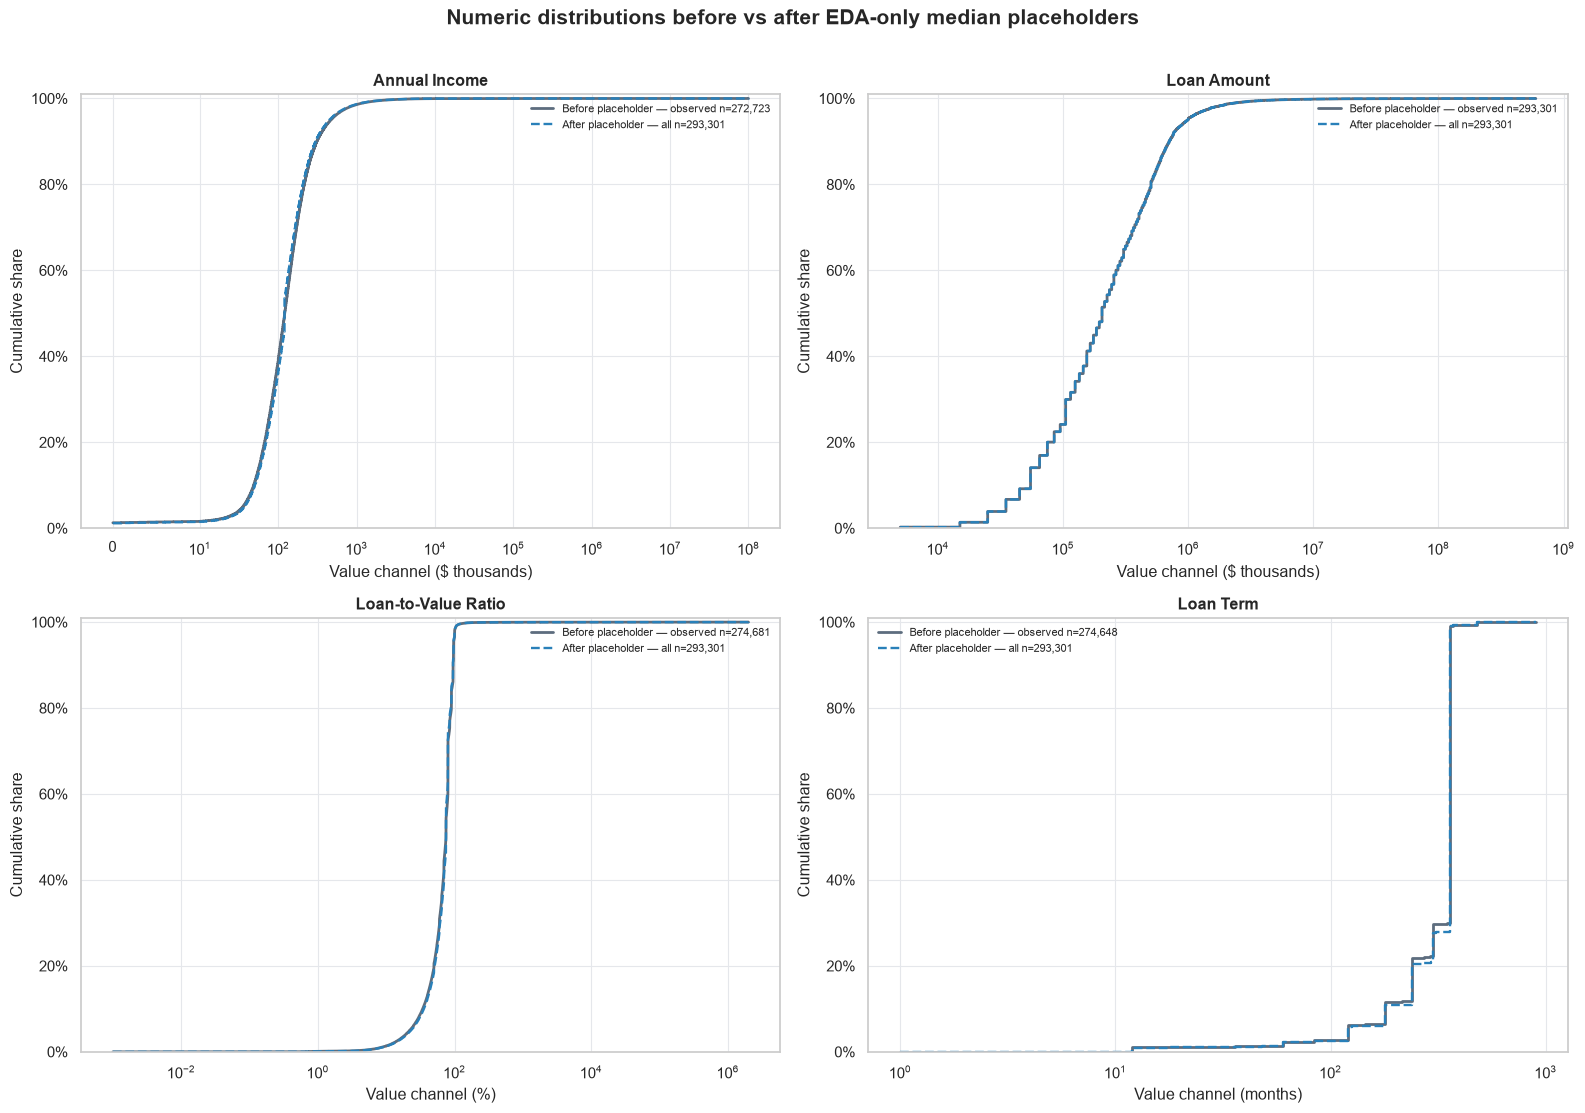

In [14]:
# EDA v2 staging — Task 05B: numeric distributions before/after placeholders
eda_v2_numeric_comparison_figure, eda_v2_numeric_comparison_axes = (
    plt.subplots(2, 2, figsize=(16, 11))
)

for axis, feature in zip(
    eda_v2_numeric_comparison_axes.flat,
    EDA_V2_NUMERIC_FEATURES,
):
    before_values = eda_v2_numeric_before[feature].dropna().to_numpy()
    after_values = eda_processed[f"{feature}_value"].to_numpy()

    before_unique, before_counts = np.unique(
        before_values, return_counts=True
    )
    after_unique, after_counts = np.unique(
        after_values, return_counts=True
    )
    before_ecdf = np.cumsum(before_counts) / before_counts.sum()
    after_ecdf = np.cumsum(after_counts) / after_counts.sum()

    axis.step(
        before_unique,
        before_ecdf,
        where="post",
        color=EDA_V2_COLORS["before"],
        linewidth=2.0,
        label=f"Before placeholder — observed n={len(before_values):,}",
    )
    axis.step(
        after_unique,
        after_ecdf,
        where="post",
        color=EDA_V2_COLORS["after"],
        linewidth=1.7,
        linestyle="--",
        label=f"After placeholder — all n={len(after_values):,}",
    )
    if feature == "income":
        axis.set_xscale("symlog", linthresh=10)
    elif (before_values > 0).all():
        axis.set_xscale("log")
    axis.set_ylim(0, 1.01)
    axis.yaxis.set_major_formatter(PercentFormatter(1))
    _unit = EDA_V2_NUMERIC_UNITS.get(feature, "")
    axis.set_title(EDA_V2_FEATURE_LABELS.get(feature, feature), fontweight="bold")
    axis.set_xlabel(f"Value channel ({_unit})" if _unit else "Value channel")
    axis.set_ylabel("Cumulative share")
    axis.grid(True, color=EDA_V2_COLORS["grid"], linewidth=0.8)
    axis.legend(frameon=False, fontsize=8)

eda_v2_numeric_comparison_figure.suptitle(
    "Numeric distributions before vs after EDA-only median placeholders",
    fontsize=15,
    fontweight="bold",
    y=1.01,
)
eda_v2_numeric_comparison_figure.tight_layout()
plt.show()


**Figure 10 — Numeric distributions before vs after EDA-only median placeholders.**  
Population: eligible Dataset B cohort. Stage: parser output (`eda_base`) vs EDA-only semantic view (`eda_processed`). Slate ECDF = observed values only (excluding NA / Exempt rows); blue ECDF = all cohort rows including median-filled rows. Units: Annual Income and Loan Amount in \$\,thousands; LTV Ratio in %; Loan Term in months. X-axis: symlog scale for Annual Income (zeros and negatives handled); log scale for positive-only features. *Caveat:* the blue curve step shift reveals the mechanical effect of inserting a point mass at the median, not a learned imputation strategy.

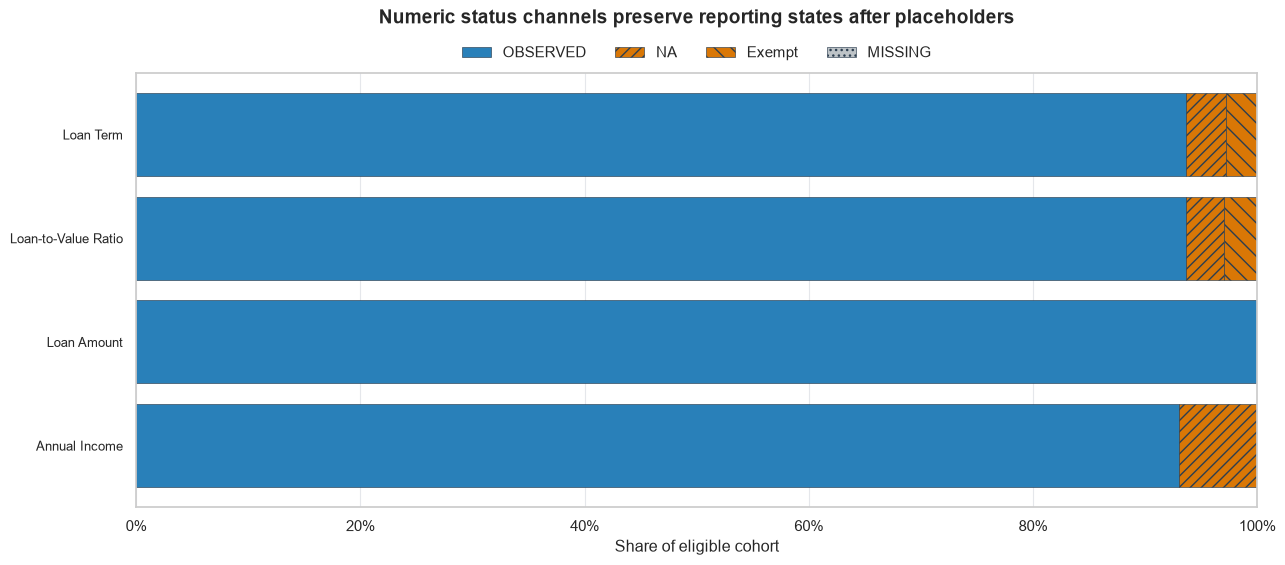

[RESULT] Numeric status preservation
            feature   status  before_n  after_n  preserved
             income OBSERVED    272723   272723       True
             income       NA     20578    20578       True
             income  MISSING         0        0       True
        loan_amount OBSERVED    293301   293301       True
        loan_amount  MISSING         0        0       True
loan_to_value_ratio OBSERVED    274681   274681       True
loan_to_value_ratio       NA      9978     9978       True
loan_to_value_ratio   Exempt      8642     8642       True
loan_to_value_ratio  MISSING         0        0       True
          loan_term OBSERVED    274648   274648       True
          loan_term       NA     10360    10360       True
          loan_term   Exempt      8293     8293       True
          loan_term  MISSING         0        0       True

[RESULT] Categorical preservation
                       feature  row_count  category_count  special_n  values_unchanged
               

In [15]:
# EDA v2 staging — Task 05C: status representation and preservation
_status_order = ("OBSERVED", "NA", "Exempt", "MISSING")
_status_colors = {
    "OBSERVED": EDA_V2_COLORS["after"],
    "NA": EDA_V2_COLORS["special"],
    "Exempt": EDA_V2_COLORS["special"],
    "MISSING": EDA_V2_COLORS["missing"],
}
_status_hatches = {
    "OBSERVED": None,
    "NA": "///",
    "Exempt": "\\\\",
    "MISSING": "...",
}
_status_share = (
    eda_v2_status_preservation
    .assign(
        share_pct=lambda frame: (
            frame["after_n"] / len(eda_processed) * 100
        )
    )
    .pivot(index="feature", columns="status", values="share_pct")
    .reindex(index=EDA_V2_NUMERIC_FEATURES, columns=_status_order)
    .fillna(0.0)
)

eda_v2_status_figure, eda_v2_status_axis = plt.subplots(
    figsize=(13, 5.8)
)
left = np.zeros(len(_status_share))
for status_level in _status_order:
    bars = eda_v2_status_axis.barh(
        _status_share.index,
        _status_share[status_level],
        left=left,
        color=_status_colors[status_level],
        edgecolor=EDA_V2_COLORS["reference"],
        linewidth=0.45,
        label=status_level,
    )
    hatch = _status_hatches[status_level]
    if hatch:
        for bar in bars:
            bar.set_hatch(hatch)
    left += _status_share[status_level].to_numpy()

# Use human-readable feature labels on y-axis (FixedLocator first)
_c24_ticks = eda_v2_status_axis.get_yticks()
eda_v2_status_axis.yaxis.set_major_locator(FixedLocator(_c24_ticks))
eda_v2_status_axis.set_yticklabels(
    [EDA_V2_FEATURE_LABELS.get(lbl.get_text(), lbl.get_text())
     for lbl in eda_v2_status_axis.get_yticklabels()],
    fontsize=9.5,
)
del _c24_ticks
eda_v2_status_axis.set_xlim(0, 100)
eda_v2_status_axis.xaxis.set_major_formatter(PercentFormatter(100))
eda_v2_status_axis.set_xlabel("Share of eligible cohort")
eda_v2_status_axis.set_ylabel("")
eda_v2_status_axis.set_title(
    "Numeric status channels preserve reporting states after placeholders",
    fontsize=14,
    fontweight="bold",
    pad=36,
)
eda_v2_status_axis.legend(
    loc="lower center",
    bbox_to_anchor=(0.5, 1.0),
    ncol=4,
    frameon=False,
)
eda_v2_status_axis.grid(
    True, axis="x", color=EDA_V2_COLORS["grid"], linewidth=0.8
)
eda_v2_status_axis.grid(False, axis="y")
eda_v2_status_figure.tight_layout()
plt.show()

print("[RESULT] Numeric status preservation")
print(eda_v2_status_preservation.to_string(index=False))
print("\n[RESULT] Categorical preservation")
print(eda_v2_category_preservation.to_string(index=False))

del _status_order, _status_colors, _status_hatches, _status_share, left


**Figure 11 — Numeric status channels (before/after EDA-only placeholders).**  
Population: eligible Dataset B cohort, *n* = 293,301. Stage: EDA-only semantic view (`eda_processed`). Each bar represents the share of rows in each reporting state (OBSERVED, NA, Exempt, MISSING) after median placeholders are inserted into the value channel. Status counts are preserved exactly; the blue segment shrinks only in the `income` bar because 20,578 NA rows receive a median fill while their status channel still reads `NA`. *Caveat:* medians are full-cohort EDA placeholders; production imputation is Train-fitted and is not represented here.

## Before/after findings

Kết luận ngắn dưới đây chỉ tổng hợp các thay đổi đã được chứng minh trong Part B; không bổ sung transformation hoặc phép phân tích mới.


In [16]:
# EDA v2 staging — Task 05D: comparison findings and acceptance gate
assert eda_base.equals(_eda_v2_base_before_task_05)
assert eda_processed.equals(_eda_v2_processed_before_task_05)
assert eda_v2_parser_change_comparison.loc[0, "before_n"] == 360
assert eda_v2_parser_change_comparison.loc[0, "after_n"] == 0
assert eda_v2_numeric_before_after["observed_values_unchanged"].all()
assert eda_v2_status_preservation["preserved"].all()
assert eda_v2_category_preservation["values_unchanged"].all()
assert eda_v2_shape_comparison["rows"].nunique() == 1
assert tuple(eda_v2_shape_comparison["columns"]) == (12, 16)
assert not eda_v2_transformation_ledger.loc[
    eda_v2_transformation_ledger["transformation"].isin(
        ["log1p", "one-hot encoding", "scaling"]
    ),
    "applied",
].any()

_largest_placeholder = (
    eda_v2_numeric_before_after.sort_values(
        ["placeholder_n", "feature"], ascending=[False, True]
    )
    .iloc[0]
)
eda_v2_task_05_findings = pd.DataFrame(
    [
        {
            "finding": "negative_income_after_parser",
            "before": 360,
            "after": 0,
            "interpretation": "negative values were deterministically mapped to zero",
        },
        {
            "finding": "largest_placeholder_feature",
            "before": int(_largest_placeholder["before_observed_n"]),
            "after": int(_largest_placeholder["after_value_n"]),
            "interpretation": (
                f"{_largest_placeholder['feature']}: "
                f"{int(_largest_placeholder['placeholder_n']):,} median placeholders "
                "with status retained"
            ),
        },
        {
            "finding": "semantic_schema_width",
            "before": eda_base.shape[1],
            "after": eda_processed.shape[1],
            "interpretation": "four numeric status channels were added",
        },
    ]
)

EDA_V2_TASK_05_SUMMARY = {
    "population_rows": len(eda_base),
    "negative_income_before_parser": 360,
    "negative_income_after_parser": 0,
    "numeric_observed_values_unchanged": True,
    "numeric_status_counts_preserved": True,
    "categorical_values_unchanged": True,
    "placeholder_cells_across_numeric_features": int(
        eda_v2_numeric_before_after["placeholder_n"].sum()
    ),
    "columns_before": eda_base.shape[1],
    "columns_after": eda_processed.shape[1],
    "log1p_comparison": "not_applicable",
    "ohe_comparison": "not_applicable",
    "sparsity_comparison": "not_applicable",
    "eda_base_unchanged": True,
    "eda_processed_unchanged": True,
}

print("[RESULT] Before/after findings")
print(eda_v2_task_05_findings.to_string(index=False))
print("\n[RESULT] Applied-transformation ledger")
print(eda_v2_transformation_ledger.to_string(index=False))
print(
    "\n[PASS] Comparisons are limited to parser and semantic-view "
    "transformations that were actually applied."
)
EDA_V2_TASK_05_SUMMARY

del (
    _eda_v2_base_before_task_05,
    _eda_v2_processed_before_task_05,
    _income_parser_audit,
    _largest_placeholder,
)


[RESULT] Before/after findings
                     finding  before  after                                          interpretation
negative_income_after_parser     360      0   negative values were deterministically mapped to zero
 largest_placeholder_feature  272723 293301 income: 20,578 median placeholders with status retained
       semantic_schema_width      12     16                 four numeric status channels were added

[RESULT] Applied-transformation ledger
           transformation  applied                                              effect
  filter eligible actions     True           383,614 raw rows -> 293,301 eligible rows
    parse negative income     True                            360 negative values -> 0
median value placeholders     True       57,851 numeric placeholders; status preserved
                    log1p    False                not created for the current EDA view
         one-hot encoding    False not created; 66-column comparison is not applicable
       

## Research findings

- Eligible Dataset B cohort có 293.301 hồ sơ và 12 predictors sau filter/parser.
- `debt_to_income_ratio` có special-state share cao nhất: 31.108 hồ sơ (10,61%).
- Với approval outcome, `debt_to_income_ratio` có association categorical mạnh nhất (bias-corrected Cramér’s V ≈ 0,5168); `loan_amount` có numeric monotonic association mạnh nhất nhưng vẫn yếu (signed Spearman ρ ≈ +0,1869).
- Association feature-to-feature mạnh nhất là `business_or_commercial_purpose × debt_to_income_ratio`, bias-corrected Cramér’s V ≈ 0,8493. Kết quả này phải được đọc cùng cấu trúc shared special states.
- Parser chuyển 360 negative income values thành 0. Sau đó semantic view thêm 57.851 median placeholders trên bốn numeric value channels nhưng giữ nguyên các status tương ứng.
- Mọi observed numeric values và tám categorical features đều không đổi giữa `eda_base` và `eda_processed`.


## Limitations

- Median placeholders được tính trên full eligible cohort chỉ để hiển thị EDA; chúng không đại diện cho Train-fitted production state.
- Notebook không triển khai model-specific `log1p`, OHE hoặc scaling, vì vậy không đưa ra so sánh distribution hoặc sparsity cho các bước chưa tồn tại.
- Target-aware figures là phân tích univariate mô tả; chúng không chứng minh quan hệ nhân quả, fairness, feature importance hoặc model performance.
- KDE chỉ hiển thị cửa sổ P1–P99 để tránh extreme tails làm phẳng mật độ; boxplots dùng toàn bộ observed values và hiển thị outlier points. Income dùng symlog, Loan Amount dùng log, còn LTV giữ thang tuyến tính với một panel full-range riêng để extreme values không làm mất khả năng đọc hộp chính.
- Outlier flags và association strengths chỉ mang tính mô tả. Không có hàng nào bị loại, clip hoặc winsorize trong các EDA views này.


## Technical assertions

Cell cuối kiểm tra xuyên suốt contract, population, parser, hai data views, before/after invariants và semantic visual system. Các assertions này xác nhận consistency trong notebook, không xác nhận production pipeline equivalence.


In [17]:
# EDA v2 — final technical and visual assertions
_EXPECTED_COLORS = {
    "before": "#5D6D7E",
    "after": "#2980B9",
    "special": "#D97706",
    "missing": "#BDC3C7",
    "invalid": "#C2410C",
    "reference": "#2C3E50",
}
assert COLORS == _EXPECTED_COLORS
assert EDA_V2_ASSOCIATION_CMAP.name == EDA_V2_ASSOCIATION_CMAP_NAME

assert EDA_V2_TASK_01_SUMMARY["feature_count"] == 12
assert EDA_V2_TASK_02_SUMMARY["filtered_rows"] == 293_301
assert EDA_V2_TASK_02_SUMMARY["invalid_n"] == 0
assert EDA_V2_TASK_02_SUMMARY["approved_rows"] == 218_760
assert EDA_V2_TASK_02_SUMMARY["denied_rows"] == 74_541
assert EDA_V2_TASK_03_SUMMARY["source_dataframe"] == "eda_base"
assert EDA_V2_TASK_03_SUMMARY["eda_base_unchanged"] is True
assert EDA_V2_TASK_03_SUMMARY["target_numeric_associations"] == 4
assert EDA_V2_TASK_03_SUMMARY["target_categorical_associations"] == 8
assert EDA_V2_TASK_03_SUMMARY["association_pairs"] == 78
assert eda_v2_association.shape == (13, 13)
assert "approval_outcome" in eda_v2_association.index
assert len(_boxplot_axes) == 3
assert [axis.get_xscale() for axis in _boxplot_axes] == [
    "symlog", "log", "linear"
]
assert all(
    any(line.get_marker() == "o" for line in axis.lines)
    for axis in _boxplot_axes
)
assert eda_v2_ltv_full_range_axis.get_xscale() == "linear"
assert EDA_V2_TASK_04_SUMMARY["columns"] == 16
assert EDA_V2_TASK_04_SUMMARY["train_fitted_production_pipeline"] is False
assert EDA_V2_TASK_05_SUMMARY["columns_before"] == 12
assert EDA_V2_TASK_05_SUMMARY["columns_after"] == 16
assert EDA_V2_TASK_05_SUMMARY["eda_base_unchanged"] is True
assert EDA_V2_TASK_05_SUMMARY["eda_processed_unchanged"] is True

assert all(
    axis.lines[0].get_color() == EDA_V2_COLORS["before"]
    and axis.lines[1].get_color() == EDA_V2_COLORS["after"]
    for axis in eda_v2_numeric_comparison_axes.flat
)
assert all(
    axis.lines[0].get_color() == EDA_V2_COLORS["reference"]
    and axis.lines[0].get_linestyle() == "--"
    for axis in eda_v2_numeric_axes[:, 0]
)
assert (
    eda_v2_association_axis.collections[0].cmap.name
    == EDA_V2_ASSOCIATION_CMAP_NAME
)
assert any(
    patch.get_hatch() not in (None, "")
    for patch in eda_v2_status_axis.patches
)
assert any(
    patch.get_hatch() not in (None, "")
    for patch in eda_v2_coverage_axis.patches
)

EDA_V2_NARRATIVE_ORDER = (
    "TL;DR",
    "Data scope",
    "Filter/parser audit",
    "Part A: Before preprocessing",
    "Part B: After preprocessing",
    "Before/after findings",
    "Research findings",
    "Limitations",
    "Technical assertions",
)
EDA_V2_TASK_06_SUMMARY = {
    "narrative_sections": len(EDA_V2_NARRATIVE_ORDER),
    "palette": COLORS,
    "before_color": EDA_V2_COLORS["before"],
    "after_color": EDA_V2_COLORS["after"],
    "special_color": EDA_V2_COLORS["special"],
    "invalid_color": EDA_V2_COLORS["invalid"],
    "reference_color": EDA_V2_COLORS["reference"],
    "association_cmap": EDA_V2_ASSOCIATION_CMAP.name,
    "special_states_use_hatch": True,
    "reference_lines_are_dashed": True,
    "all_task_summaries_passed": True,
}

print("[PASS] Research narrative sections are declared in final reading order.")
print("[PASS] Shared semantic palette is consistent across EDA v2 figures.")
print("[PASS] Final technical assertions passed for Tasks 01–06.")
EDA_V2_TASK_06_SUMMARY

del _EXPECTED_COLORS


[PASS] Research narrative sections are declared in final reading order.
[PASS] Shared semantic palette is consistent across EDA v2 figures.
[PASS] Final technical assertions passed for Tasks 01–06.
